# TEP 공정 이상 탐지·고장 진단 — 전체 연구 과정과 결과

**Phase 1 데이터 감사 → Phase 2 모델 개발 → 최종 평가·설명·한계**  
분석 기록: 2026-11-10 · 자료: Tennessee Eastman Process 시뮬레이션

이 노트북은 이미 수행한 연구를 한 흐름으로 설명하는 **종합 결과 노트북**이다. 저장된 출력에 표와 그림을 포함하므로 실행하지 않아도 결과를 읽을 수 있다. `Run All`은 검증된 산출물에서 표·그림을 다시 구성하며 **모델을 다시 학습하거나 Test로 설정을 조정하지 않는다**.

| 읽는 순서 | 내용 |
|---|---|
| 1–5 | 핵심 결과, 작업 흐름, 공정·변수, 데이터 확보, 품질·호환성 |
| 6–10 | 실행 단위 분할, 라벨·시간창, 모델 학습, 검증 기준 선택, 모델 구조 |
| 11–15 | 전체 Test 성능, 혼동행렬, 고장별 차이·지연, 실제 경보, 불균형 처리 |
| 16–20 | SHAP·센서 반응, 미지 고장, 실행 비용·검증, 한계, 재현 방법 |

> 고장이라고 가정한 **조건부 분류 성능**, 탐지 실패까지 포함한 **end-to-end 성능**, **실제 물리적 원인 식별**은 서로 다른 개념이다.

In [1]:
from pathlib import Path
import json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, Markdown, Image, HTML

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'configs/phase2.json').exists() and (p / 'reports/tables').exists()), None)
if ROOT is None:
    raise FileNotFoundError('프로젝트 루트 또는 notebooks 폴더에서 실행하세요.')
TABLES = ROOT / 'reports/tables'
P2 = TABLES / 'phase2'
FIGURES = ROOT / 'reports/figures'
SOURCES = ROOT / 'reports/sources/phase2'

# 이 두 값으로 14·16절의 실제 사례를 바꿀 수 있다. 선택은 표시만 바꾸며 모델·임계값은 변경하지 않는다.
FAULT_TO_INSPECT = 9
RUN_TO_INSPECT = 1
assert 1 <= FAULT_TO_INSPECT <= 20 and 1 <= RUN_TO_INSPECT <= 500

def read_table(name, phase2=True):
    return pd.read_csv((P2 if phase2 else TABLES) / name)
def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))
def show_table(frame, title, source, formats=None):
    styled = (frame.style.hide(axis='index')
              .format(formats or {}, na_rep='미검출 / 해당 없음')
              .set_caption(title)
              .set_properties(**{'text-align':'left', 'padding':'7px 10px', 'font-size':'13px'})
              .set_table_styles([
                  {'selector':'caption', 'props':[('text-align','left'),('font-weight','bold'),('font-size','16px'),('padding','12px 0')]},
                  {'selector':'th', 'props':[('background-color','#eaf1f5'),('padding','8px 10px'),('text-align','left')]},
                  {'selector':'td', 'props':[('border-bottom','1px solid #e2e8ed')]}
              ]))
    display(styled)
    display(Markdown(f'*출처: `{source}`*'))
def note(title, body):
    display(HTML(f'<div style="border-left:4px solid #257d91;padding:12px 16px;background:#f0f6f8;margin:14px 0"><b>{title}</b><br>{body}</div>'))
def show_image(relative, caption):
    path = FIGURES / relative
    if not path.exists():
        raise FileNotFoundError(path)
    display(Image(filename=str(path)))
    display(Markdown(f'*{caption}*'))
def boxes(ax, nodes, edges):
    for key, (x,y,w,h,label,color) in nodes.items():
        ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.015',fc=color,ec='#82939e',lw=1))
        ax.text(x+w/2,y+h/2,label,ha='center',va='center',fontsize=10)
    for start,end in edges:
        a,b=nodes[start],nodes[end]
        if start=='now' and end=='head':
            ax.annotate('',xy=(b[0]+b[2]/2,b[1]),xytext=(a[0]+a[2],a[1]+a[3]/2),
                        arrowprops={'arrowstyle':'->','color':'#526777','lw':1.5,
                                    'connectionstyle':'angle,angleA=0,angleB=90,rad=12'})
            continue
        sx,sy=a[0]+a[2]/2,a[1]+a[3]/2
        ex,ey=b[0]+b[2]/2,b[1]+b[3]/2
        if abs(ex-sx)>abs(ey-sy):
            sx += np.sign(ex-sx)*a[2]/2;ex -= np.sign(ex-sx)*b[2]/2
        else:
            sy += np.sign(ey-sy)*a[3]/2;ey -= np.sign(ey-sy)*b[3]/2
        ax.annotate('',xy=(ex,ey),xytext=(sx,sy),arrowprops={'arrowstyle':'->','color':'#526777','lw':1.5})
    ax.set(xlim=(-.025,1.025),ylim=(0,1));ax.axis('off')

plt.rcParams.update({'font.family':'Malgun Gothic', 'axes.unicode_minus':False,
                     'font.size':10, 'figure.dpi':130})
pd.options.display.max_colwidth = 90
cfg = read_json(ROOT / 'configs/phase2.json')
lock = read_json(ROOT / 'models/phase2/selection_lock.json')
dense = read_json(SOURCES / 'dense_metrics.json')
summary = read_table('model_performance_summary.csv')
per_fault = read_table('primary_dense_per_fault.csv')
delays = read_table('dense_detection_delays.csv')
episodes = read_table('dense_alarm_episodes.csv')
shap_rank = read_table('shap_sensor_rankings.csv')
test_models = read_table('test_comparison.csv')
primary = dense['joint_primary']
display(Markdown(f'**프로젝트:** `{ROOT}`  |  **주 모델:** `{lock["primary_model"]}`'))

**프로젝트:** `C:\Users\fl27\Documents\ChatGPT\TEP`  |  **주 모델:** `CNN1D_Temporal_balanced_s42`

## 1. 먼저 보는 핵심 결과

검증 데이터에서 선택한 주 모델은 **1D-CNN 단일 모델(seed 42)**이다. 별도 이진 XGBoost는 정상/고장만 예측하며, 두 모델을 결합한 새로운 cascade의 성능을 주장하지 않았다.

아래는 **전체 유효 Test 시점** 결과다. 뒤의 모델 비교 표는 공통 간격으로 추출한 별도 평가 시점의 3개 seed 평균이므로 수치가 조금 다르다.

In [2]:
main_events = episodes[(episodes.system=='joint_primary') & (episodes.fault>0)]
headline = pd.DataFrame([
    ['탐지 Precision', f"{primary['detection_precision']:.2%}", '고장 경보 중 실제 명목 고장 샘플 비율'],
    ['탐지 Recall', f"{primary['detection_recall']:.2%}", '명목 고장 샘플 중 임계값을 넘은 비율'],
    ['탐지 F1', f"{primary['detection_f1']:.4f}", 'Precision·Recall의 조화 평균'],
    ['20종 조건부 분류 Macro F1', f"{primary['diagnosis_macro_f1']:.4f}", '실제 고장 구간을 안다고 가정한 분류'],
    ['21상태 end-to-end Macro F1', f"{primary['end_to_end_macro_f1']:.4f}", '탐지 실패를 포함한 정상+고장 분류'],
    ['정상 샘플 FAR', f"{primary['sample_false_alarm_rate']:.2%}", '정상 샘플의 단일 임계값 초과율'],
    ['검출된 실행의 지연 중앙값', f'{main_events.detection_delay_minutes.median():.0f}분', '미검출 실행은 지연 계산에서 제외'],
    ['평가 시점 수', f"{primary['samples']:,}", 'Test의 최초19개 warm-up 관측은 제외']
],columns=['지표','결과','해석'])
show_table(headline,'주 모델 전체 Test 성능','reports/sources/phase2/dense_metrics.json; dense_alarm_episodes.csv')
note('전체 점수만으로는 드러나지 않는 약점',
     'Fault 9와15의 탐지+정확한 ID Recall은 각각 약0.04%, 0%다. 미지 고장 실험의 Recall도 약2.6%로 낮았다. '
     '이 결과를 일반적인 원인 진단 능력이나 실제 설비 검증으로 확대해서 해석하지 않는다.')

지표,결과,해석
탐지 Precision,99.70%,고장 경보 중 실제 명목 고장 샘플 비율
탐지 Recall,86.74%,명목 고장 샘플 중 임계값을 넘은 비율
탐지 F1,0.9277,Precision·Recall의 조화 평균
20종 조건부 분류 Macro F1,0.9115,실제 고장 구간을 안다고 가정한 분류
21상태 end-to-end Macro F1,0.8558,탐지 실패를 포함한 정상+고장 분류
정상 샘플 FAR,1.11%,정상 샘플의 단일 임계값 초과율
검출된 실행의 지연 중앙값,48분,미검출 실행은 지연 계산에서 제외
평가 시점 수,"9,880,500",Test의 최초19개 warm-up 관측은 제외


*출처: `reports/sources/phase2/dense_metrics.json; dense_alarm_episodes.csv`*

## 2. 실제 수행한 연구 흐름

Phase 1에서 데이터를 확인한 뒤 승인을 받아 Phase 2를 수행했다. **모델 선택과 임계값 결정은 Validation에서 끝냈고**, Test 결과를 보고 모델을 바꾸지 않았다.

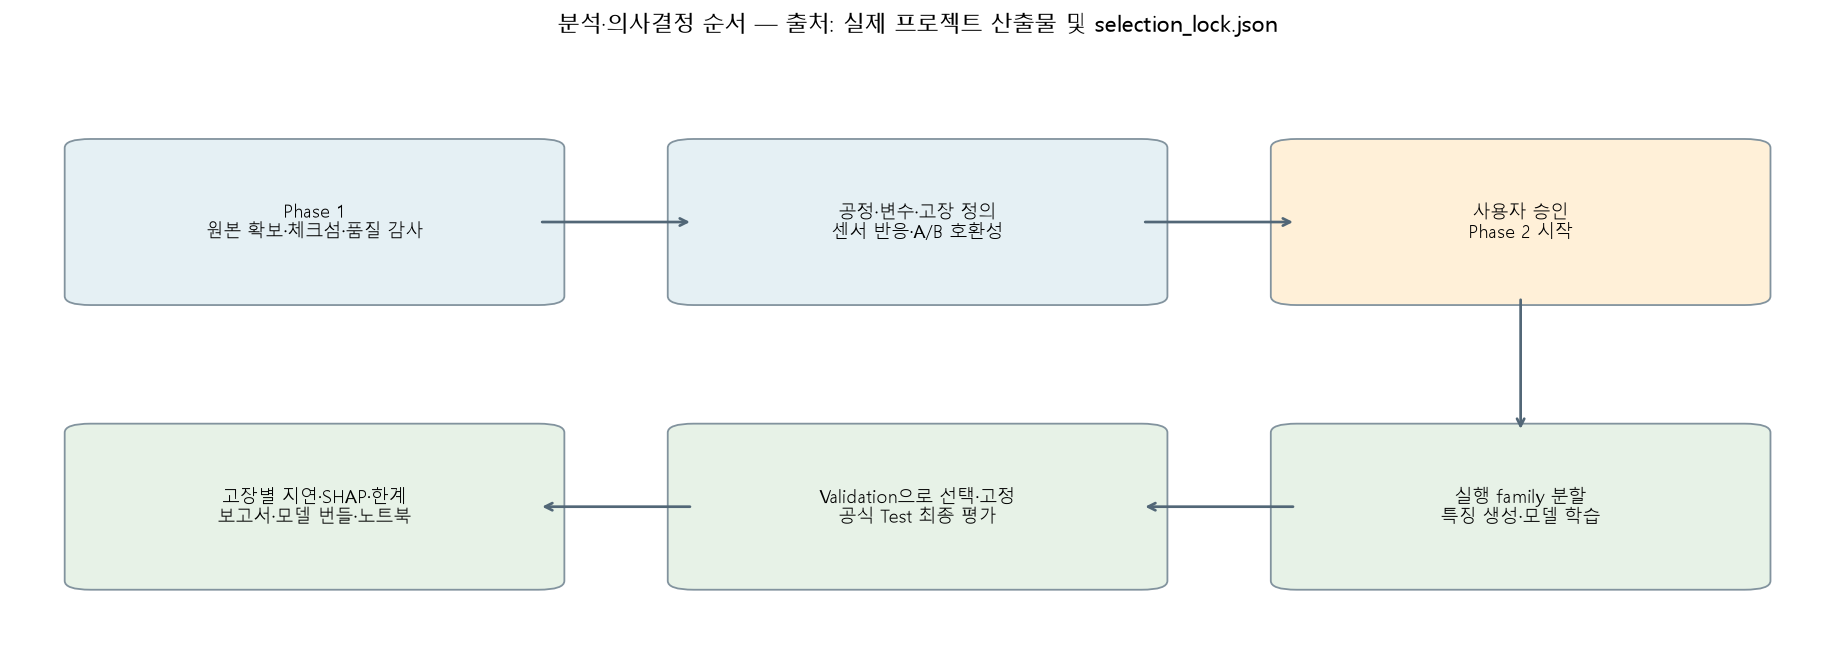

In [3]:
fig,ax=plt.subplots(figsize=(14,5),layout='constrained')
nodes={
 'a':(.02,.60,.26,.25,'Phase 1\n원본 확보·체크섬·품질 감사','#e5f0f4'),
 'b':(.37,.60,.26,.25,'공정·변수·고장 정의\n센서 반응·A/B 호환성','#e5f0f4'),
 'c':(.72,.60,.26,.25,'사용자 승인\nPhase 2 시작','#fff0d8'),
 'd':(.72,.12,.26,.25,'실행 family 분할\n특징 생성·모델 학습','#e7f2e7'),
 'e':(.37,.12,.26,.25,'Validation으로 선택·고정\n공식 Test 최종 평가','#e7f2e7'),
 'f':(.02,.12,.26,.25,'고장별 지연·SHAP·한계\n보고서·모델 번들·노트북','#e7f2e7')}
boxes(ax,nodes,[('a','b'),('b','c'),('c','d'),('d','e'),('e','f')])
ax.set_title('분석·의사결정 순서 — 출처: 실제 프로젝트 산출물 및 selection_lock.json',pad=15)
plt.show()

## 3. TEP 공정과 변수의 물리적 의미

원료가 Reactor에 공급되고, Condenser·Separator·Stripper를 거쳐 제품으로 나간다. 일부 기상은 Compressor를 통해 재순환된다. 제어기는 온도·압력·수위·유량을 보상하므로 **가장 크게 변한 변수와 고장의 원인은 다를 수 있다**.

다음은 배포 시뮬레이터의 장치를 요약한 개념도이며 상세 배관도(P&ID)가 아니다. 변수 사전의 단위와 설명은 **Dataset A 소스 기준**이며 B의 동일 단위·보정 조건까지 확정한 것은 아니다.

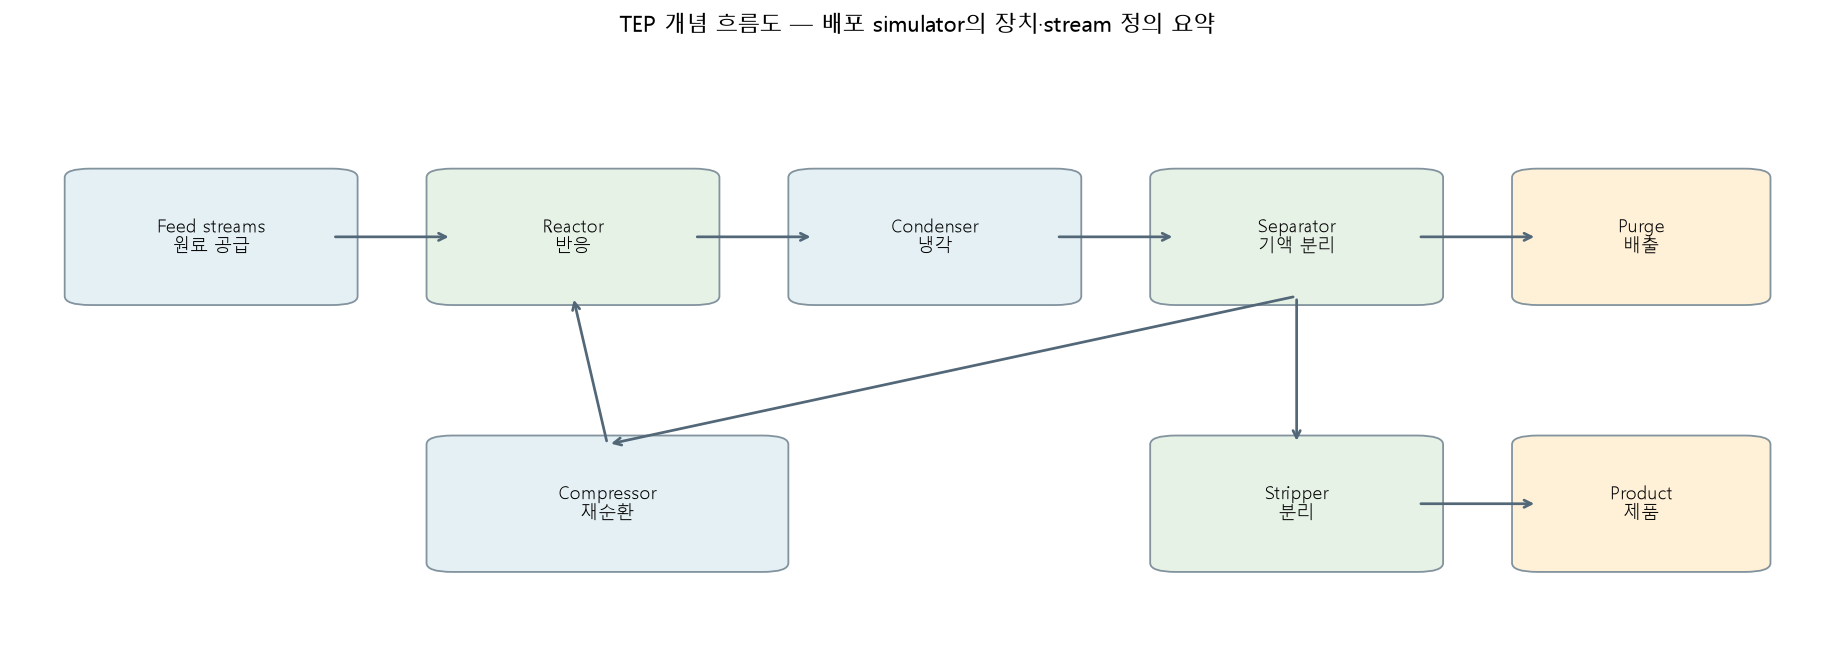

변수,물리적 의미(A 소스),원문 단위(A),장치
xmeas_1,A Feed,kscmh,Feed
xmeas_4,A and C Feed,kscmh,Feed
xmeas_7,Reactor Pressure,kPa gauge,Reactor
xmeas_8,Reactor Level,%,Reactor
xmeas_9,Reactor Temperature,Deg C,Reactor
xmeas_11,Product Sep Temp,Deg C,Separator
xmeas_15,Stripper Level,%,Stripper
xmeas_18,Stripper Temp,Deg C,Stripper
xmeas_20,Compressor Work,kW,Compressor
xmeas_21,Reactor Coolant Temp,Deg C,Reactor cooling


*출처: `reports/tables/variable_dictionary.csv; TEplot.m; temexd_mod.c`*

In [4]:
fig,ax=plt.subplots(figsize=(14,5),layout='constrained')
nodes={
 'feed':(.02,.60,.14,.20,'Feed streams\n원료 공급','#e5f0f4'),
 'react':(.23,.60,.14,.20,'Reactor\n반응','#e7f2e7'),
 'cond':(.44,.60,.14,.20,'Condenser\n냉각','#e5f0f4'),
 'sep':(.65,.60,.14,.20,'Separator\n기액 분리','#e7f2e7'),
 'strip':(.65,.15,.14,.20,'Stripper\n분리','#e7f2e7'),
 'product':(.86,.15,.12,.20,'Product\n제품','#fff0d8'),
 'comp':(.23,.15,.18,.20,'Compressor\n재순환','#e5f0f4'),
 'purge':(.86,.60,.12,.20,'Purge\n배출','#fff0d8')}
boxes(ax,nodes,[('feed','react'),('react','cond'),('cond','sep'),('sep','purge'),('sep','strip'),('strip','product'),('sep','comp'),('comp','react')])
ax.set_title('TEP 개념 흐름도 — 배포 simulator의 장치·stream 정의 요약',pad=15)
plt.show()
variables=read_table('variable_dictionary.csv',False)
key=['xmeas_1','xmeas_4','xmeas_7','xmeas_8','xmeas_9','xmeas_11','xmeas_15','xmeas_18','xmeas_20','xmeas_21','xmeas_22','xmv_10','xmv_11']
v=variables[variables.variable.isin(key)][['variable','meaning','unit','device']].rename(columns={'variable':'변수','meaning':'물리적 의미(A 소스)','unit':'원문 단위(A)','device':'장치'})
show_table(v,'주요 센서·조작 변수','reports/tables/variable_dictionary.csv; TEplot.m; temexd_mod.c')

## 4. 데이터 확보와 고장 카탈로그

- **Dataset A:** 사용자 제공 GitHub 폴더. Excel 214개가 Git LFS 포인터였으므로 실제 파일을 복원하고 SHA256을 대조했다.
- **Dataset B:** 사용자 제공 RData 4개. Harvard V1.0 공식 MD5가 모두 일치했다.
- **학습은 B만 사용했다.** A와 B를 행 단위로 합치지 않았다.

A의 `xmv-1~41` 헤더는 `simout`에 붙인 잘못된 명명으로 측정값이다. B의 실제 조작변수 `xmv_1~11`과 혼동하면 안 된다.

In [5]:
a_inventory=read_table('a_inventory.csv',False)
a_hash=read_table('a_run_hashes.csv',False)
b_inventory=read_table('b_inventory.csv',False)
inventory=pd.DataFrame([
 ['A: GitHub Excel',len(a_inventory),int(a_inventory.rows.sum()),41,'Time(h) 별도','1분','1·3·4, 고장은1만'],
 ['B: Harvard RData',len(b_inventory),int(b_inventory.rows.sum()),52,'faultNumber/simulationRun/sample','3분','공식 API에서 미확인']
],columns=['자료','파일 수','행 수','공정 변수 수','메타데이터','저장 주기','운전모드'])
show_table(inventory,'확보한 데이터 구성','a_inventory.csv; b_inventory.csv',{'행 수':'{:,.0f}'})
bview=b_inventory[['file','rows','run_groups','md5_verified','missing']].rename(columns={'file':'파일','rows':'샘플 수','run_groups':'상태별 실행 궤적 수','md5_verified':'공식 MD5 일치','missing':'결측'})
show_table(bview,'B 파일별 실제 검사 결과','reports/tables/b_inventory.csv',{'샘플 수':'{:,.0f}','상태별 실행 궤적 수':'{:,.0f}'})
catalog=read_table('fault_catalog.csv',False)
c=catalog[['fault','cause','form','definition_status']].rename(columns={'fault':'Fault','cause':'공개 시나리오(A 참조)','form':'발생 형태','definition_status':'검증 상태'})
show_table(c,'고장 정의와 미확인 원인','reports/tables/fault_catalog.csv')

자료,파일 수,행 수,공정 변수 수,메타데이터,저장 주기,운전모드
A: GitHub Excel,214,"649,479",41,Time(h) 별도,1분,"1·3·4, 고장은1만"
B: Harvard RData,4,"15,330,000",52,faultNumber/simulationRun/sample,3분,공식 API에서 미확인


*출처: `a_inventory.csv; b_inventory.csv`*

파일,샘플 수,상태별 실행 궤적 수,공식 MD5 일치,결측
TEP_FaultFree_Testing.RData,"480,000",500,True,0
TEP_FaultFree_Training.RData,"250,000",500,True,0
TEP_Faulty_Testing.RData,"9,600,000","10,000",True,0
TEP_Faulty_Training.RData,"5,000,000","10,000",True,0


*출처: `reports/tables/b_inventory.csv`*

Fault,공개 시나리오(A 참조),발생 형태,검증 상태
1,A/C 원료 비율(B 일정),Step,문서/소스 일치
2,B 조성(A/C 일정),Step,문서/소스 일치
3,D 원료 온도,Step,문서/소스 일치
4,Reactor 냉각수 입구 온도,Step,문서/소스 일치
5,Condenser/Separator 냉각수 입구 온도,Step,문서/소스 일치
6,A 원료 공급 손실,Step,문서/소스 일치
7,C header 압력 손실,Step,문서/소스 일치
8,A/B/C 원료 조성,Random,문서/소스 일치
9,D 원료 온도,Random,문서/소스 일치
10,C 원료 온도,Random,문서/소스 일치


*출처: `reports/tables/fault_catalog.csv`*

## 5. 데이터 품질과 A/B 호환성에서 발견한 문제

A에서는 완전히 같은 측정 시계열이 여러 파일에 반복됐다. Fault 6은 약17시간에서 기록이 끝났다. B에서는 전체 궤적 중복은 없었지만 **같은 run 번호의 정상·여러 고장 실행이 초기 구간을 공유**했다. 따라서 파일 수·행 수·독립 난수 family 수를 별도로 센다.

Fault 16~20은 공개 원인 `UNKNOWN`을 유지했다. A Fault21은 README의 밸브 고정과 배포 소스의 원료 온도 교란 정의가 충돌하며 B에는21이 없다.

검사,결과,영향
A 결측 / 비유한값,0 / 0,제거·보간 없이 원본 수치를 유지
A 파일 / 고유 측정 시계열,214 / 168,고유 시계열 수도 난수 독립성을 보장하지 않음
A 추가 중복 파일,46,같은 Fault 내부의 전체 동일 시계열
B 실행 궤적 / 초기20샘플 고유 해시,"21,000 / 1,000",전체 Train/Test에서 각500개 run family
B Train/Test 초기 해시 교집합,0,공식 seed 비중복 설명과 함께 검토


*출처: `a_inventory.csv; a_run_hashes.csv; b_all_runs.csv`*

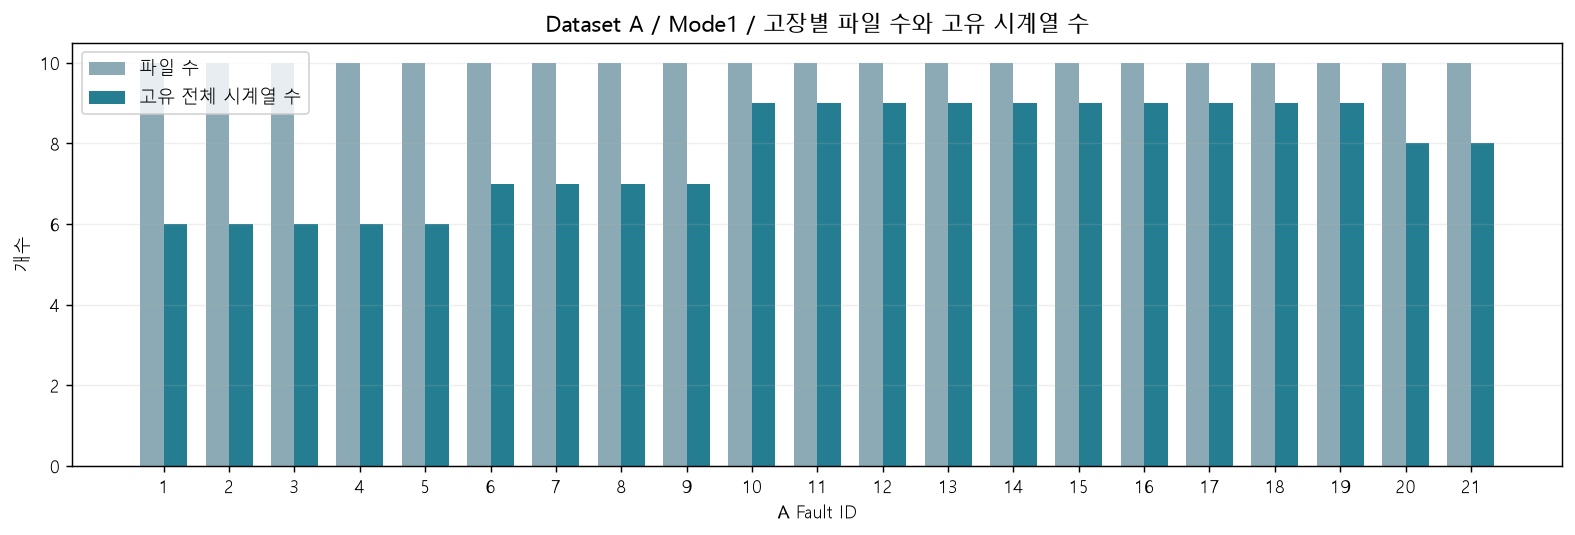

비교 항목,GitHub A,Harvard B,판정
변수 개수,41 measured,41 measured + 11 manipulated,불일치
변수 순서,"Time, xmv-1~41 (실제 simout)","3 metadata, xmeas_1~41, xmv_1~11",부분 대응; 헤더 수정 근거 필요
변수 정의,로컬 소스의 측정 정의,원래 변수명 유지; 상세 단위표 없음,공통 계열이나 동일 조건 미확정
샘플링 주기,1분 (실측),3분 (공식),불일치
Fault ID,"1~21, 21 충돌",1~20,21 제외; 16~20 원인 UNKNOWN
운전 모드,"1,3,4; 고장은 1만",공식 API에 명시 없음,미확인
주입 시각,모델 명목 10h; 파일별 미확인,Training 1h / Testing 8h (공식),불일치
시뮬레이터 조건,"개정 C, Simulink; batch seed rand()","시드 분할 설명, 제어기/빌드 미기재",동일성 미확인
독립성,"중복 시계열 존재, seed 로그 없음",Train/Test seeds non-overlap (공식),A-B 독립성 확증 불가


*출처: `reports/tables/compatibility.csv`*

In [6]:
b_runs=read_table('b_all_runs.csv',False)
audit=pd.DataFrame([
 ['A 결측 / 비유한값',f'{a_inventory.missing.sum()} / {a_inventory.nonfinite.sum()}','제거·보간 없이 원본 수치를 유지'],
 ['A 파일 / 고유 측정 시계열',f'{len(a_hash)} / {a_hash.full.nunique()}','고유 시계열 수도 난수 독립성을 보장하지 않음'],
 ['A 추가 중복 파일',str(a_hash.full.duplicated().sum()),'같은 Fault 내부의 전체 동일 시계열'],
 ['B 실행 궤적 / 초기20샘플 고유 해시',f'{len(b_runs):,} / {b_runs.prefix20.nunique():,}','전체 Train/Test에서 각500개 run family'],
 ['B Train/Test 초기 해시 교집합',str(len(set(b_runs[b_runs.file.str.contains('Training')].prefix20)&set(b_runs[b_runs.file.str.contains('Testing')].prefix20))),'공식 seed 비중복 설명과 함께 검토']
],columns=['검사','결과','영향'])
show_table(audit,'샘플 수와 독립성의 구분','a_inventory.csv; a_run_hashes.csv; b_all_runs.csv')
counts=read_table('a_class_counts.csv',False).query('mode==1 and fault>0')
fig,ax=plt.subplots(figsize=(12,4),layout='constrained')
ax.bar(counts.fault-.18,counts.files,.36,label='파일 수',color='#8baab5')
ax.bar(counts.fault+.18,counts.unique_series,.36,label='고유 전체 시계열 수',color='#257d91')
ax.set(xticks=range(1,22),xlabel='A Fault ID',ylabel='개수',title='Dataset A / Mode1 / 고장별 파일 수와 고유 시계열 수')
ax.legend();ax.grid(axis='y',alpha=.2);plt.show()
show_table(read_table('compatibility.csv',False),'두 데이터셋의 호환성 판정','reports/tables/compatibility.csv')
note('주입 시각에 관한 증거 수준',
     'A 배포 모델에는10h delay가 연결되지만 파일별 생성 로그는 없어 명목 시각으로만 표시했다. '
     'B는 공식 설명의Training1h/Test8h를 라벨 기준으로 사용했다. 두 버전을 같은 실험 조건으로 간주하지 않았다.')

## 6. 학습·검증·시험 분할과 누수 방지

공식 Training의 500개 run family를 **학습400·검증100**으로 나눴다. 같은 `simulationRun`의 모든 Fault·정상 실행은 함께 이동한다. 공식 Test의500개 family는 별도다. 분할 사이에 숫자1~500이 반복돼도 같은 전역 실행 ID를 뜻하지 않는다.

전처리·클래스 가중치·resampling은 Train에서만 구성했다. scaler의 Train 전용 fit, 미래 참조, 실행 경계, 초기 궤적 중복을 자동 테스트로 확인했다.

In [7]:
split=read_json(ROOT/'reports/sources/phase2_split_manifest.json')
cohorts=pd.DataFrame([
 ['Train',len(split['train']),8400,4200000,101200,'학습 endpoint stride40; 고장 정상 prefix 중복 제외'],
 ['Validation',len(split['validation']),2100,1050000,102900,'비교 endpoint stride10'],
 ['Test 공통 비교',len(split['test']),10500,10080000,997500,'모든 후보가 동일 endpoint stride10'],
 ['Test 전체 평가',len(split['test']),10500,10080000,primary['samples'],'선택한 두 모델, 모든 유효 endpoint']
],columns=['용도','run family 수','상태별 궤적 수','원자료 행 수','사용한 창/시점 수','표본 구성'])
show_table(cohorts,'실행 family·궤적·관측 시점의 구분','phase2_split_manifest.json; configs/phase2.json; dense_metrics.json',{'원자료 행 수':'{:,.0f}','사용한 창/시점 수':'{:,.0f}'})
assert not set(split['train']) & set(split['validation'])
assert set(split['train']) | set(split['validation']) == set(range(500))
display(Markdown('**분할 확인:** Train/Validation run index 교집합은0개다. JSON의 index는0부터 시작하며 실제 simulationRun은index+1이다.'))

용도,run family 수,상태별 궤적 수,원자료 행 수,사용한 창/시점 수,표본 구성
Train,400,8400,"4,200,000","101,200",학습 endpoint stride40; 고장 정상 prefix 중복 제외
Validation,100,2100,"1,050,000","102,900",비교 endpoint stride10
Test 공통 비교,500,10500,"10,080,000","997,500",모든 후보가 동일 endpoint stride10
Test 전체 평가,500,10500,"10,080,000","9,880,500","선택한 두 모델, 모든 유효 endpoint"


*출처: `phase2_split_manifest.json; configs/phase2.json; dense_metrics.json`*

**분할 확인:** Train/Validation run index 교집합은0개다. JSON의 index는0부터 시작하며 실제 simulationRun은index+1이다.

## 7. 라벨·시간축·특징 구성

Training은 sample20까지 정상, sample21부터 고장으로 라벨링했다. Test는 sample160까지 정상, sample161부터 고장이다. 실제 센서 반응이 늦어져도 고장 구간을 임의로 삭제하지 않았다.

시간은 **sample×3분**으로 정의했다. 첫 기록이0분인지3분인지에 관한 원 생성 로그가 없어 한 샘플 수준의 시간 해석 불확실성이 남는다. 과거20개 관측의 첫·끝 점 간격은57분이며 처음19개 샘플은 warm-up이다.

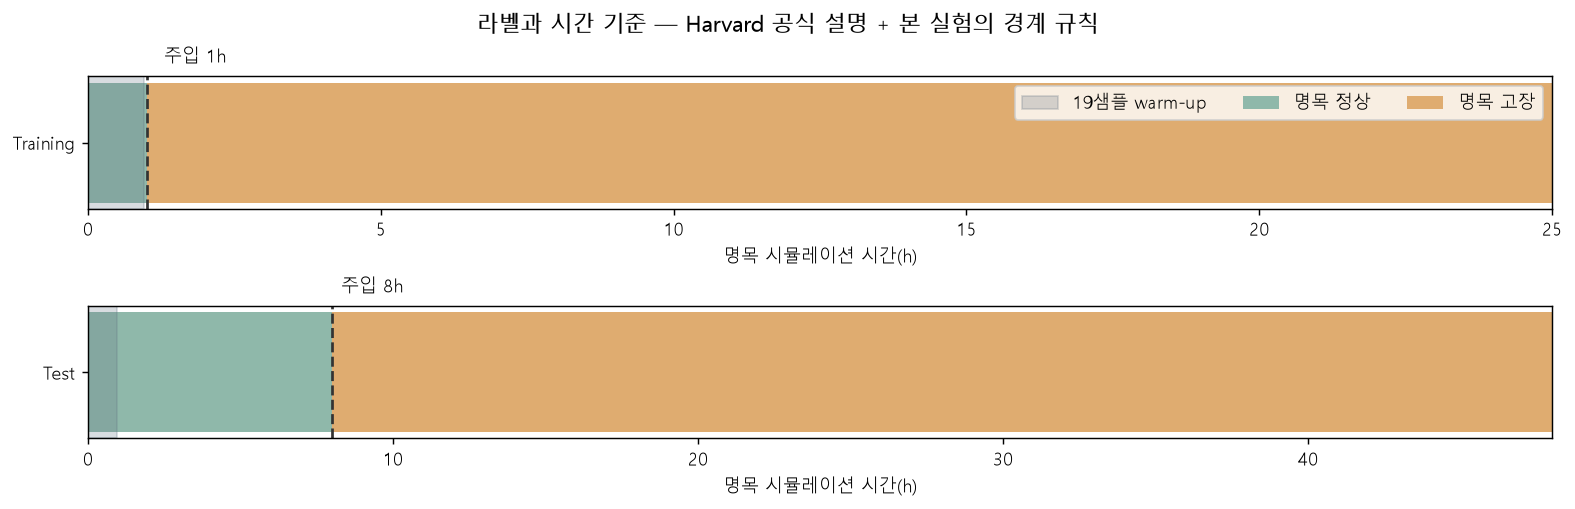

특징 집합,입력,차원,규칙
Current,현재52개 측정/조작값,52,"현재 관측만, 비교 시점은 다른 집합과 동일"
Statistical,현재값 + 과거20개 평균·표준편차·최소·최대·변화율,312,"변화율 분모57분, 미래값 사용 없음"
Temporal,시간 순서를 유지한 과거20개×52개 변수,20 × 52,창이 다른 실행을 가로지르지 않음


*출처: `src/features/phase2.py; configs/phase2.json`*

In [8]:
fig,axes=plt.subplots(2,1,figsize=(12,3.8),layout='constrained')
for ax,label,total,boundary in [(axes[0],'Training',25,1),(axes[1],'Test',48,8)]:
    ax.barh([0],[boundary],left=0,color='#8fb8aa',height=.45,label='명목 정상')
    ax.barh([0],[total-boundary],left=boundary,color='#dfac70',height=.45,label='명목 고장')
    ax.axvspan(0,19*3/60,color='#657684',alpha=.25,label='19샘플 warm-up')
    ax.axvline(boundary,color='#333333',ls='--');ax.text(boundary+.3,.30,f'주입 {boundary}h',fontsize=10)
    ax.set(xlim=(0,total),yticks=[0],yticklabels=[label],xlabel='명목 시뮬레이션 시간(h)')
axes[0].legend(loc='upper right',ncol=3);fig.suptitle('라벨과 시간 기준 — Harvard 공식 설명 + 본 실험의 경계 규칙')
plt.show()
features=pd.DataFrame([
 ['Current','현재52개 측정/조작값','52','현재 관측만, 비교 시점은 다른 집합과 동일'],
 ['Statistical','현재값 + 과거20개 평균·표준편차·최소·최대·변화율','312','변화율 분모57분, 미래값 사용 없음'],
 ['Temporal','시간 순서를 유지한 과거20개×52개 변수','20 × 52','창이 다른 실행을 가로지르지 않음']
],columns=['특징 집합','입력','차원','규칙'])
show_table(features,'모델 입력의 차이','src/features/phase2.py; configs/phase2.json')
note('학습 표본 추출의 제한',
     'Train endpoint를sample20,60,…,500으로 추출했다. 따라서 명목 주입 직후sample21~59, 약2시간의 '
     '초기 과도 창을 직접 학습하지 않았다. 모든 학습 실행을 포함했지만 모든 행을fit한 모델은 아니다. Test는 이 초기 구간도 포함한다.')

## 8. 학습한 모델과 학습 경과

기본 모델3종은 Current/Statistical을, 시계열 모델3종은 동일한 Temporal 창을 비교했다. 대표 설정은 seed42·7·2026으로 반복했다. Logistic Regression의 결정적 해법에서는 seed를 달리해도 결과가 같을 수 있다.

시계열 모델은 Train 채널 평균·표준편차로 정규화했다. 최대8epoch, patience2, Adam lr0.001, batch256이었다. PyTorch는 RTX3060에서, XGBoost는 실제 GPU probe가 fallback한 뒤 CPU8 threads로 실행했다.

모델,특징,고정 주요 설정,실행
Logistic Regression,Current / Statistical,"lbfgs, C1, max_iter250",CPU
Random Forest,Current / Statistical,"100trees, depth20, min_leaf3",CPU8 threads
XGBoost,Current / Statistical,"100rounds, depth4, lr0.1, hist",CPU8 threads
LSTM,Temporal,hidden64 + 현재값 연결 + Dense64,GPU
GRU,Temporal,hidden64 + 현재값 연결 + Dense64,GPU
1D-CNN,Temporal,Conv64(k5) → Conv64(k3) → 평균 → 현재값 연결,GPU


*출처: `src/models/phase2.py; src/models/temporal.py; phase2/environment.json`*

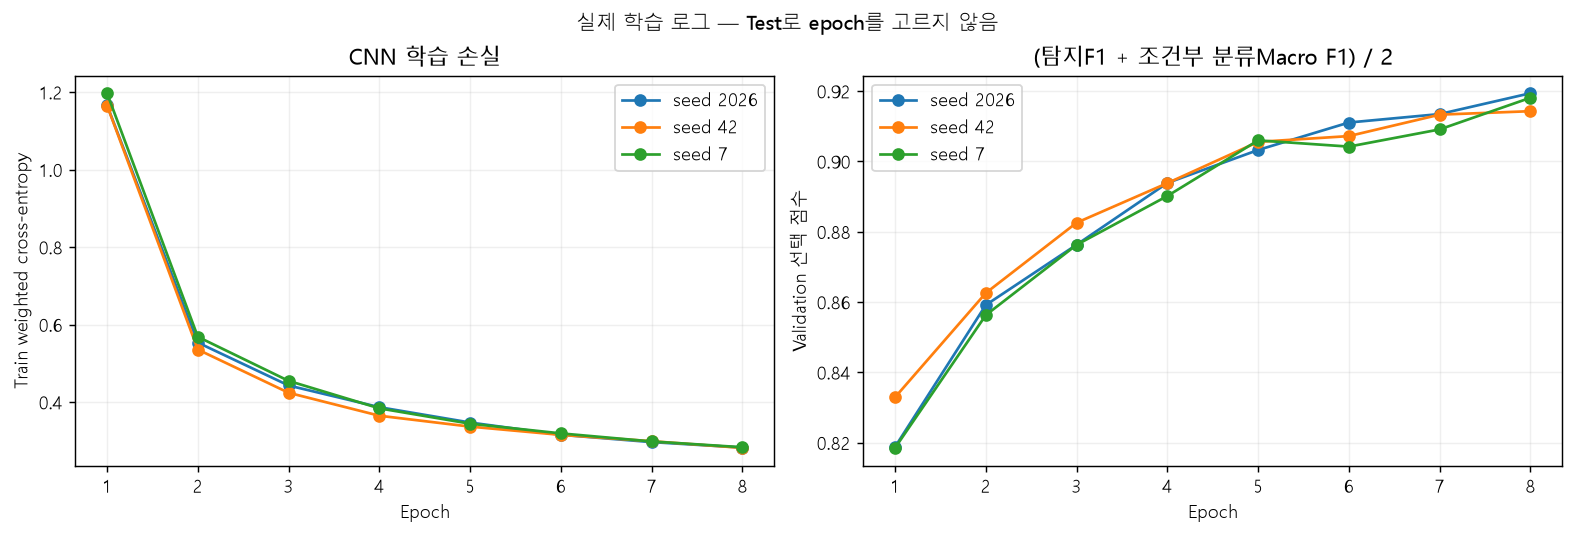

In [9]:
model_plan=pd.DataFrame([
 ['Logistic Regression','Current / Statistical','lbfgs, C1, max_iter250','CPU'],
 ['Random Forest','Current / Statistical','100trees, depth20, min_leaf3','CPU8 threads'],
 ['XGBoost','Current / Statistical','100rounds, depth4, lr0.1, hist','CPU8 threads'],
 ['LSTM','Temporal','hidden64 + 현재값 연결 + Dense64','GPU'],
 ['GRU','Temporal','hidden64 + 현재값 연결 + Dense64','GPU'],
 ['1D-CNN','Temporal','Conv64(k5) → Conv64(k3) → 평균 → 현재값 연결','GPU']
],columns=['모델','특징','고정 주요 설정','실행'])
show_table(model_plan,'모델 계열과 실제 설정','src/models/phase2.py; src/models/temporal.py; phase2/environment.json')
history=read_table('temporal_history.csv')
chosen_history=history[history.model_id.str.startswith('CNN1D_')]
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for name,g in chosen_history.groupby('model_id'):
    seed=name.split('_s')[-1]
    axes[0].plot(g.epoch,g.loss,'o-',label=f'seed {seed}')
    axes[1].plot(g.epoch,g.selection_score,'o-',label=f'seed {seed}')
axes[0].set(xlabel='Epoch',ylabel='Train weighted cross-entropy',title='CNN 학습 손실')
axes[1].set(xlabel='Epoch',ylabel='Validation 선택 점수',title='(탐지F1 + 조건부 분류Macro F1) / 2')
for ax in axes:ax.legend();ax.grid(alpha=.2)
fig.suptitle('실제 학습 로그 — Test로 epoch를 고르지 않음',fontsize=11);plt.show()

## 9. Validation 선택과 공통 Test 비교

기본 모델은 seed42로 natural/balanced를 비교한 뒤 검증 우수 설정을 나머지 seed로 반복했다. 선택 점수는 **검증 탐지F1과 고장 분류Macro F1의 평균을3개 seed로 평균한 값**이다. 주 모델은 대표 seed42의 단일 checkpoint이며 ensemble이 아니다.

아래 Test 비교는 모든 모델에 동일한 **997,500개 시점**을 사용했다. 오차막대는 seed 간 표준편차이며, 뒤의 run-family bootstrap 신뢰구간과 다르다.

모델,특징,Validation 선택점수,Test 탐지F1 평균,탐지F1 SD,Test 분류Macro F1 평균,분류F1 SD,Test FAR 평균
CNN1D,Temporal,0.9173,0.9333,0.0027,0.9180,0.0024,0.0110
LSTM,Temporal,0.9153,0.9315,0.0050,0.9159,0.0046,0.0110
GRU,Temporal,0.9136,0.9310,0.0032,0.9121,0.0031,0.0096
XGBoost,Statistical,0.8891,0.9052,0.0004,0.8940,0.0004,0.0072
LogisticRegression,Statistical,0.8667,0.8919,0.0000,0.8560,0.0000,0.0085
RandomForest,Statistical,0.8655,0.8910,0.0009,0.8608,0.0010,0.0077
XGBoost,Current,0.8196,0.8529,0.0017,0.8035,0.0010,0.0110
RandomForest,Current,0.7602,0.8009,0.0031,0.7378,0.0027,0.0103
LogisticRegression,Current,0.6084,0.7183,0.0000,0.5161,0.0000,0.0105


*출처: `reports/tables/phase2/model_performance_summary.csv`*

**고정 모델:** `CNN1D_Temporal_balanced_s42` · **선택 고정 시각:** 2026-11-10T16:20:48.200692+09:00 (Asia/Seoul)

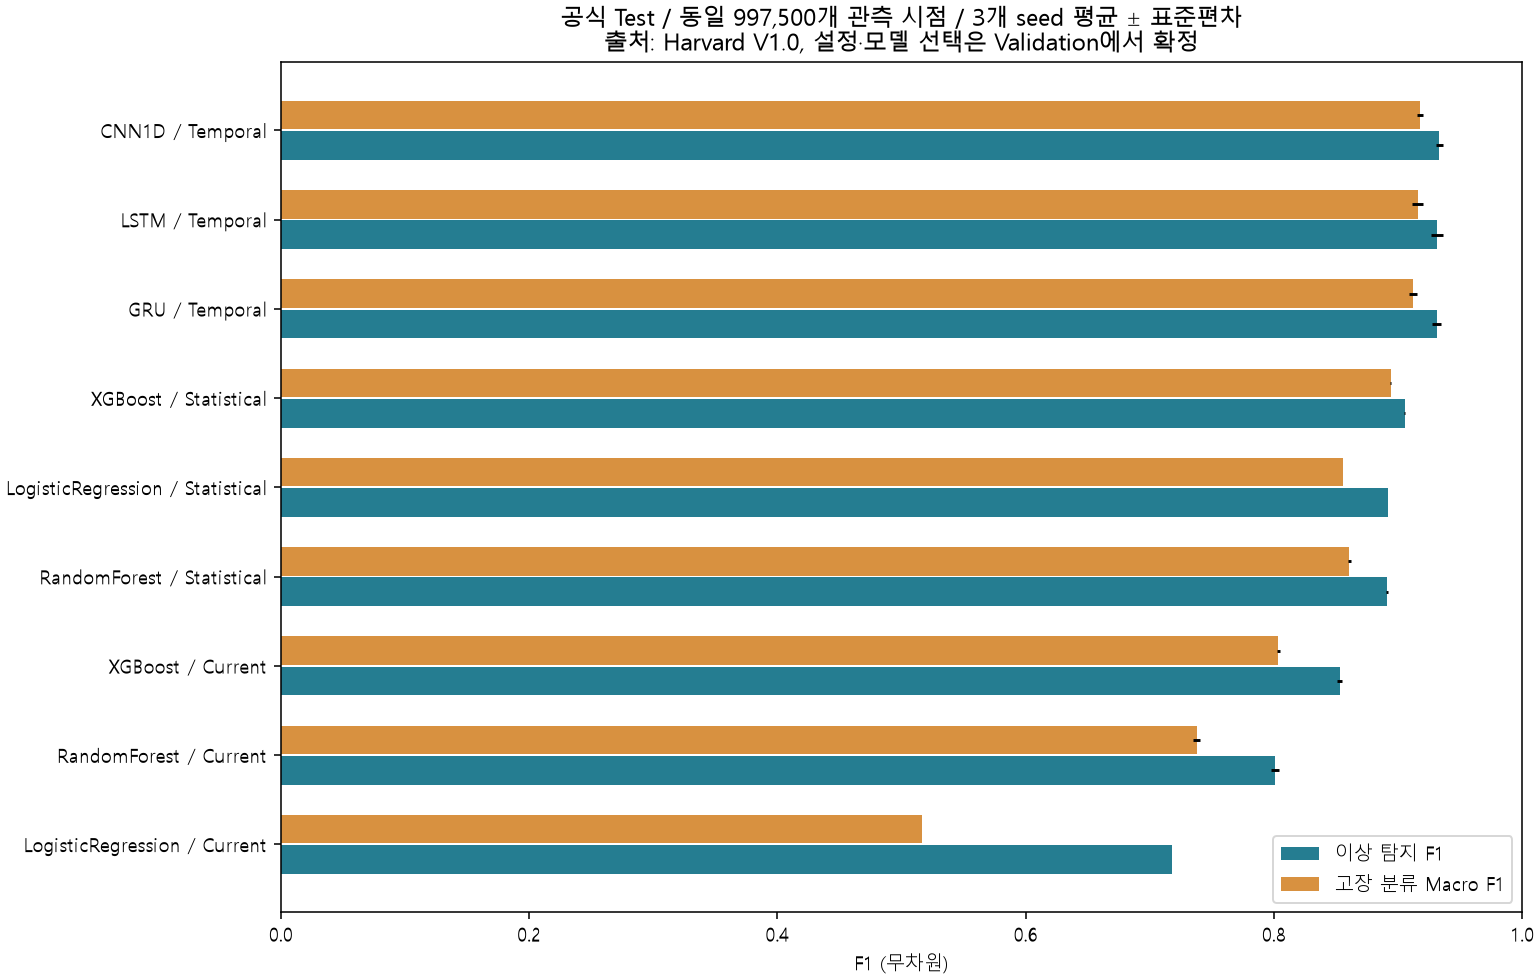

*공통 Test 시점 비교. 모델 순서는 Validation 선택점수 기준이며 Test 수치로 모델을 교체하지 않았다.*

In [10]:
view=summary[['model','features','validation_selection_mean','detection_f1_mean','detection_f1_sd','diagnosis_macro_f1_mean','diagnosis_macro_f1_sd','sample_FAR_mean']].rename(columns={
 'model':'모델','features':'특징','validation_selection_mean':'Validation 선택점수',
 'detection_f1_mean':'Test 탐지F1 평균','detection_f1_sd':'탐지F1 SD',
 'diagnosis_macro_f1_mean':'Test 분류Macro F1 평균','diagnosis_macro_f1_sd':'분류F1 SD','sample_FAR_mean':'Test FAR 평균'})
show_table(view,'공통 Test 시점의 3개 seed 평균 ± SD','reports/tables/phase2/model_performance_summary.csv',
           {c:'{:.4f}' for c in view.select_dtypes('number').columns})
locked_local=pd.Timestamp(lock['locked_utc']).tz_convert('Asia/Seoul')
display(Markdown(f'**고정 모델:** `{lock["primary_model"]}` · **선택 고정 시각:** {locked_local.isoformat()} (Asia/Seoul)'))
show_image('phase2/model_comparison.png','공통 Test 시점 비교. 모델 순서는 Validation 선택점수 기준이며 Test 수치로 모델을 교체하지 않았다.')

## 10. 선택한 1D-CNN의 구조와 동작

과거 창 안의 국소 패턴을 두 합성곱 층으로 요약하고 현재52개 값도 함께 연결한다. 합성곱의 padding은 이미 관측된 창 안에서만 적용되며 예측 시각 이후의 데이터를 넣지 않는다. 21개 출력은 정상0과 Fault1~20이다.

고장 확률은 `1 − P(normal)`로 계산하고, 임계값을 넘었을 때 Fault1~20 중 최대 확률의 ID를 출력한다. **고장 조건부 분류**에서는 정상 확률을 제외하고 ID를 고르므로 end-to-end보다 좋은 점수가 나올 수 있다.

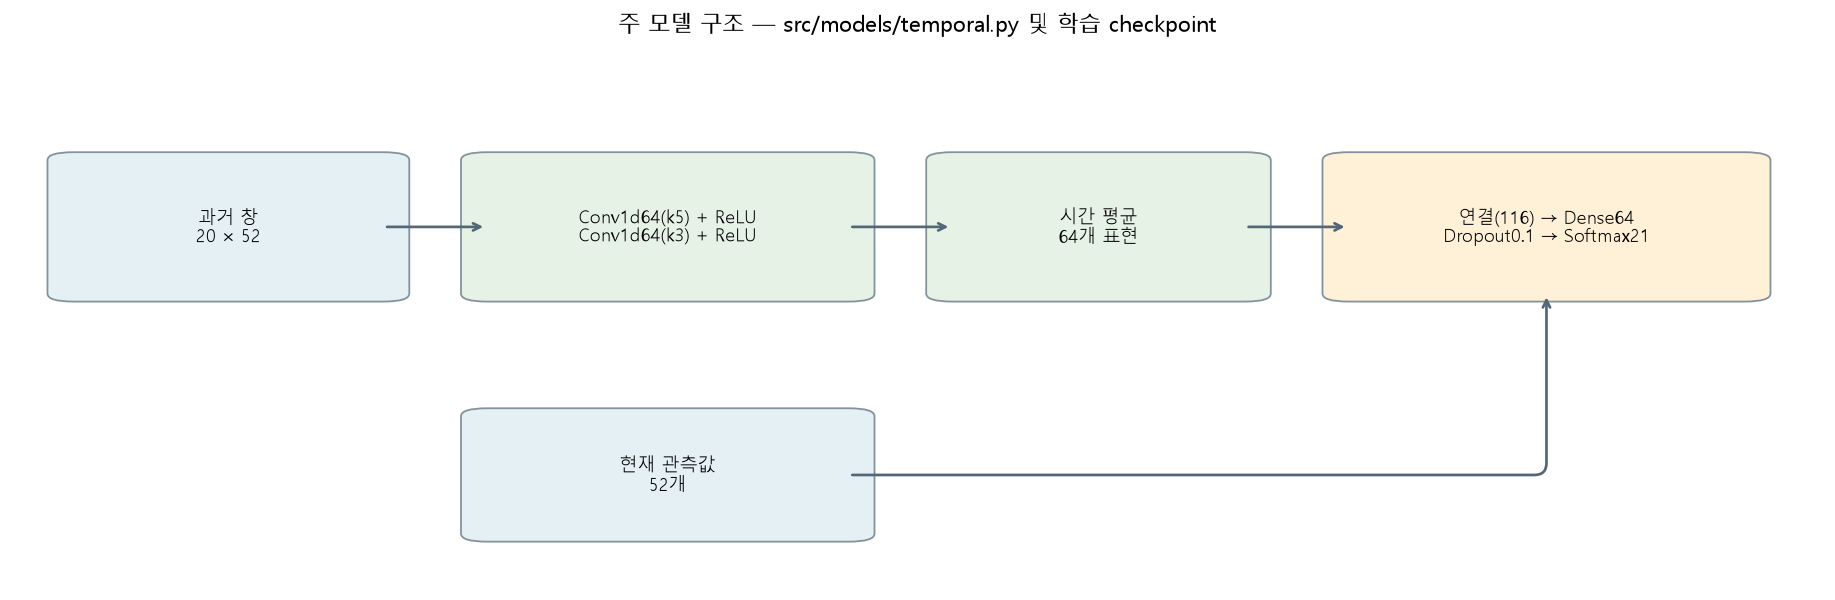

**학습 파라미터:** 37,909개 · **고정 탐지 임계값:** 0.967192 · **입력 메타 열:** 사용하지 않음

In [11]:
fig,ax=plt.subplots(figsize=(14,4.5),layout='constrained')
nodes={
 'input':(.01,.55,.18,.25,'과거 창\n20 × 52','#e5f0f4'),
 'conv':(.25,.55,.21,.25,'Conv1d64(k5) + ReLU\nConv1d64(k3) + ReLU','#e7f2e7'),
 'pool':(.52,.55,.17,.25,'시간 평균\n64개 표현','#e7f2e7'),
 'now':(.25,.10,.21,.22,'현재 관측값\n52개','#e5f0f4'),
 'head':(.75,.55,.23,.25,'연결(116) → Dense64\nDropout0.1 → Softmax21','#fff0d8')}
boxes(ax,nodes,[('input','conv'),('conv','pool'),('pool','head'),('now','head')])
ax.set_title('주 모델 구조 — src/models/temporal.py 및 학습 checkpoint',pad=12);plt.show()
parameters=(52*64*5+64)+(64*64*3+64)+(116*64+64)+(64*21+21)
assert parameters==37909
display(Markdown(f'**학습 파라미터:** {parameters:,}개 · **고정 탐지 임계값:** {primary["threshold"]:.6f} · **입력 메타 열:** 사용하지 않음'))

## 11. 주 모델 전체 Test 성능과 불확실성

다음은 선택한 seed42 주 모델을 **매 유효 시점 9,880,500개**에 평가한 결과다. 처음19개 관측을 제외하며 고장 직후 센서 반응이 없는 구간은 유지했다. 별도 이진 탐지기와 주 모델은 같은 전 구간에서 각각 평가했다.

ROC-AUC는 순위 구분 능력이고, PR-AUC는 average precision(AP) 정의다. 학습·평가의 클래스 비율이 다르므로 AP 하나만으로 적합성을 판단하지 않는다.

In [12]:
metric_names={
 'detection_precision':'탐지 Precision','detection_recall':'탐지 Recall','detection_f1':'탐지 F1',
 'detection_macro_f1':'이진 Macro F1','detection_balanced_accuracy':'이진 Balanced Accuracy',
 'detection_roc_auc':'탐지 ROC-AUC','detection_pr_auc':'탐지 PR-AUC(AP)',
 'sample_false_alarm_rate':'정상 샘플 FAR','diagnosis_macro_f1':'20종 조건부 분류Macro F1',
 'diagnosis_roc_auc_macro_ovr':'분류 Macro ROC-AUC(OVR)',
 'diagnosis_pr_auc_macro':'분류 Macro AP','end_to_end_macro_f1':'21상태 end-to-end Macro F1'}
full=pd.DataFrame([{'지표':label,'주 CNN':primary[key],
                   '별도 이진 XGBoost':dense['dedicated_binary'].get(key,np.nan)}
                  for key,label in metric_names.items()])
show_table(full,'전체 유효 Test 시점 — 동일 지표의 두 독립 모델 비교','phase2/dense_metrics.json',{'주 CNN':'{:.4f}','별도 이진 XGBoost':'{:.4f}'})
ci=read_table('primary_cluster_bootstrap_ci.csv').rename(columns={'metric':'지표','lower_95':'95% 하한','upper_95':'95% 상한'})
ci['지표']=ci['지표'].map(lambda x:metric_names.get(x,x))
show_table(ci,'주 모델 run-family cluster bootstrap 95% 구간','primary_cluster_bootstrap_ci.csv',{'95% 하한':'{:.4f}','95% 상한':'{:.4f}'})
note('신뢰구간의 표본 단위',
     'Test run family500개를 모든 Fault와 함께500회 재표집했다. 같은 실행의 시계열 행을 독립 표본으로 세지 않았다. '
     '이 구간은 이번 시뮬레이터·고정 모델의 Test 불확실성이며 다른 공정으로의 일반화 구간이 아니다.')

지표,주 CNN,별도 이진 XGBoost
탐지 Precision,0.9970,0.9970
탐지 Recall,0.8674,0.8098
탐지 F1,0.9277,0.8937
이진 Macro F1,0.8512,0.8004
이진 Balanced Accuracy,0.9282,0.8997
탐지 ROC-AUC,0.9539,0.9394
탐지 PR-AUC(AP),0.9901,0.9866
정상 샘플 FAR,0.0111,0.0105
20종 조건부 분류Macro F1,0.9115,미검출 / 해당 없음
분류 Macro ROC-AUC(OVR),0.9937,미검출 / 해당 없음


*출처: `phase2/dense_metrics.json`*

지표,95% 하한,95% 상한
탐지 F1,0.9273,0.9280
정상 샘플 FAR,0.0094,0.0129
20종 조건부 분류Macro F1,0.9107,0.9124
21상태 end-to-end Macro F1,0.8551,0.8565


*출처: `primary_cluster_bootstrap_ci.csv`*

## 12. 혼동행렬: 조건부 분류와 실제 경보 결과의 차이

아래 21상태 혼동행렬에서는 임계값 미달을 정상0으로 처리한다. Fault9와15의 상당 부분이 정상으로 빠지므로 **고장 구간을 미리 알고 분류한 점수**만 보면 이 문제를 놓칠 수 있다.

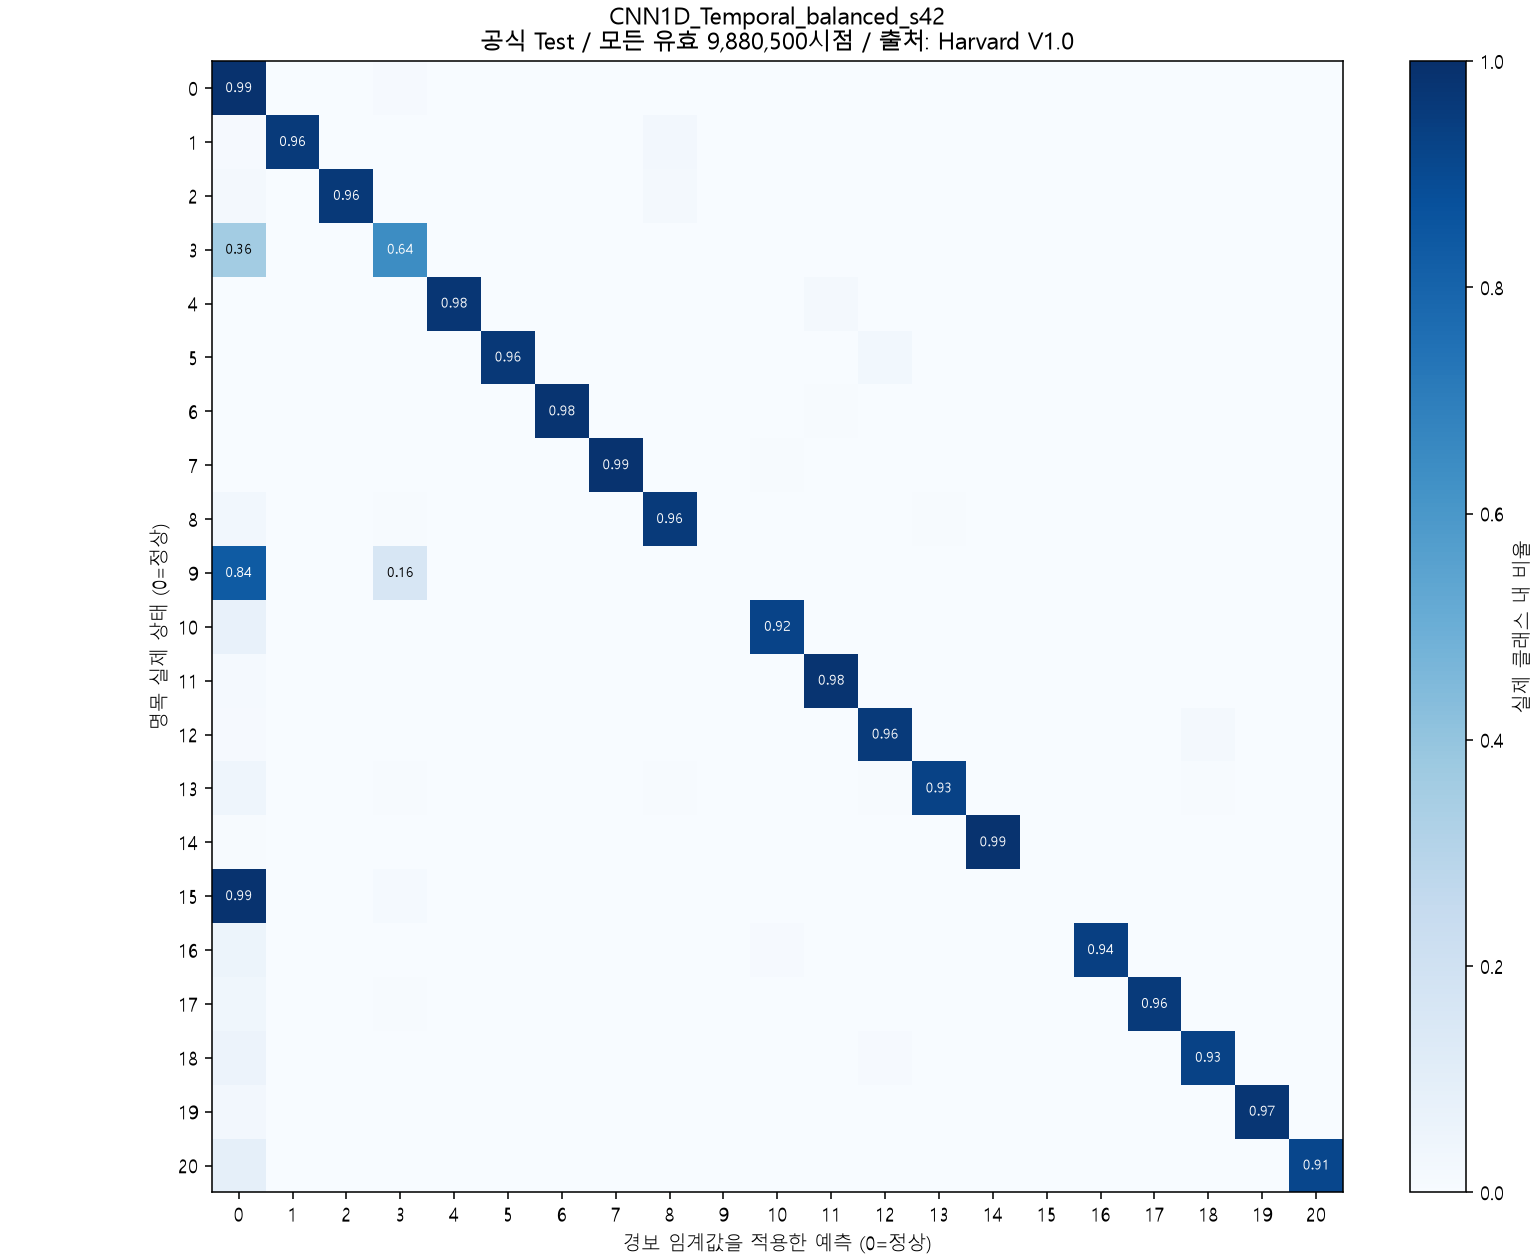

*행 기준 정규화. 실제 상태별 예측 비율, 전체 유효 Test 시점.*

실제 상태,Precision,Recall,F1,샘플 수
0,0.6368,0.9889,0.7747,"1,880,500"
1,0.9983,0.9606,0.9791,"400,000"
2,0.9995,0.9615,0.9801,"400,000"
3,0.7179,0.6430,0.6783,"400,000"
4,0.9979,0.9750,0.9863,"400,000"
5,0.9987,0.9648,0.9815,"400,000"
6,0.9998,0.9820,0.9908,"400,000"
7,0.9969,0.9882,0.9925,"400,000"
8,0.9494,0.9575,0.9535,"400,000"
9,0.1377,0.0004,0.0008,"400,000"


*출처: `primary_dense_classification_report.csv`*

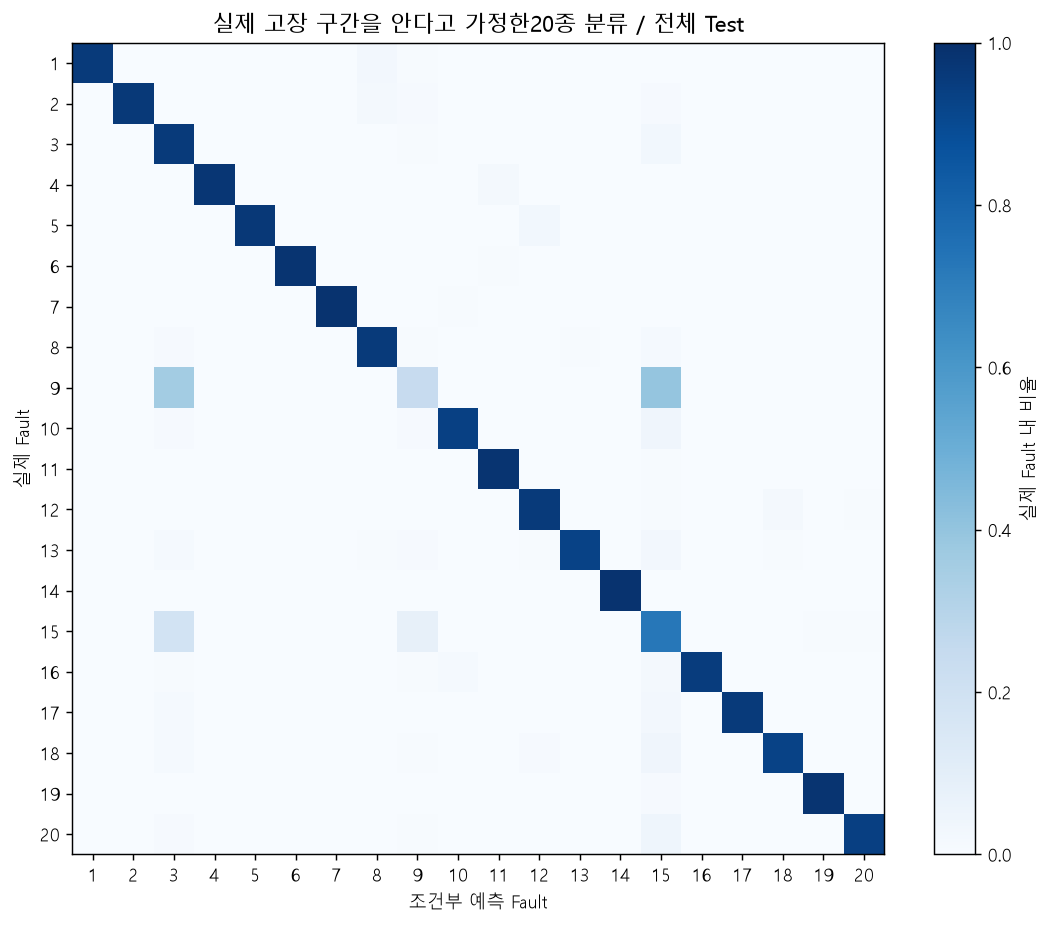

In [13]:
show_image('phase2/primary_confusion.png','행 기준 정규화. 실제 상태별 예측 비율, 전체 유효 Test 시점.')
classes=read_table('primary_dense_classification_report.csv').rename(columns={'fault':'실제 상태','precision':'Precision','recall':'Recall','f1':'F1','support':'샘플 수'})
show_table(classes,'경보 임계값을 적용한 상태별 성능','primary_dense_classification_report.csv',{'Precision':'{:.4f}','Recall':'{:.4f}','F1':'{:.4f}','샘플 수':'{:,.0f}'})
conditional=np.load(P2/'primary_conditional_diagnosis_confusion.npy')
fig,ax=plt.subplots(figsize=(9,7),layout='constrained')
im=ax.imshow(conditional/np.maximum(conditional.sum(1,keepdims=True),1),vmin=0,vmax=1,cmap='Blues')
ax.set(xticks=range(20),yticks=range(20),xticklabels=range(1,21),yticklabels=range(1,21),
       xlabel='조건부 예측 Fault',ylabel='실제 Fault',title='실제 고장 구간을 안다고 가정한20종 분류 / 전체 Test')
fig.colorbar(im,ax=ax,label='실제 Fault 내 비율');plt.show()

## 13. 고장별 성능과 탐지 지연

고장별로 각각400,000개의 post-injection 샘플을 평가했다. 조건부 분류 Recall과 end-to-end Recall은 다르다. 예를 들어 Fault15는 고장이라고 알고 분류하면 ID를 맞히는 경우가 있지만, 실제 임계값을 적용하면 대부분 정상으로 처리됐다.

지연은 **검출된 실행만** 계산했다. 미검출 실행을0분으로 채우지 않았다. 실행 검출률은 주입 후40시간 안에 한 번이라도3연속 경보가 발생한 비율이며 정확한 ID를 요구하지 않는다.

Fault,고장 샘플 수,탐지 Recall,조건부 분류Recall,end-to-end Recall
1,"400,000",99.07%,96.06%,96.06%
2,"400,000",98.11%,96.14%,96.14%
3,"400,000",64.44%,96.05%,64.30%
4,"400,000",99.86%,97.50%,97.50%
5,"400,000",99.68%,96.48%,96.48%
6,"400,000",99.76%,98.20%,98.20%
7,"400,000",99.66%,98.82%,98.82%
8,"400,000",97.22%,95.78%,95.75%
9,"400,000",16.49%,24.32%,0.04%
10,"400,000",92.67%,93.57%,92.21%


*출처: `primary_dense_per_fault.csv`*

Fault,실행 수,검출 실행,실행 검출률,미검출률,검출 지연 중앙값(분),검출 지연 P90(분)
1,500,500,100.00%,0.00%,33.0,36.0
2,500,500,100.00%,0.00%,54.0,60.0
3,500,500,100.00%,0.00%,54.0,123.0
4,500,500,100.00%,0.00%,12.0,15.0
5,500,500,100.00%,0.00%,18.0,21.0
6,500,500,100.00%,0.00%,15.0,15.0
7,500,500,100.00%,0.00%,18.0,18.0
8,500,500,100.00%,0.00%,69.0,108.0
9,500,500,100.00%,0.00%,187.5,543.0
10,500,500,100.00%,0.00%,87.0,141.0


*출처: `dense_detection_delays.csv`*

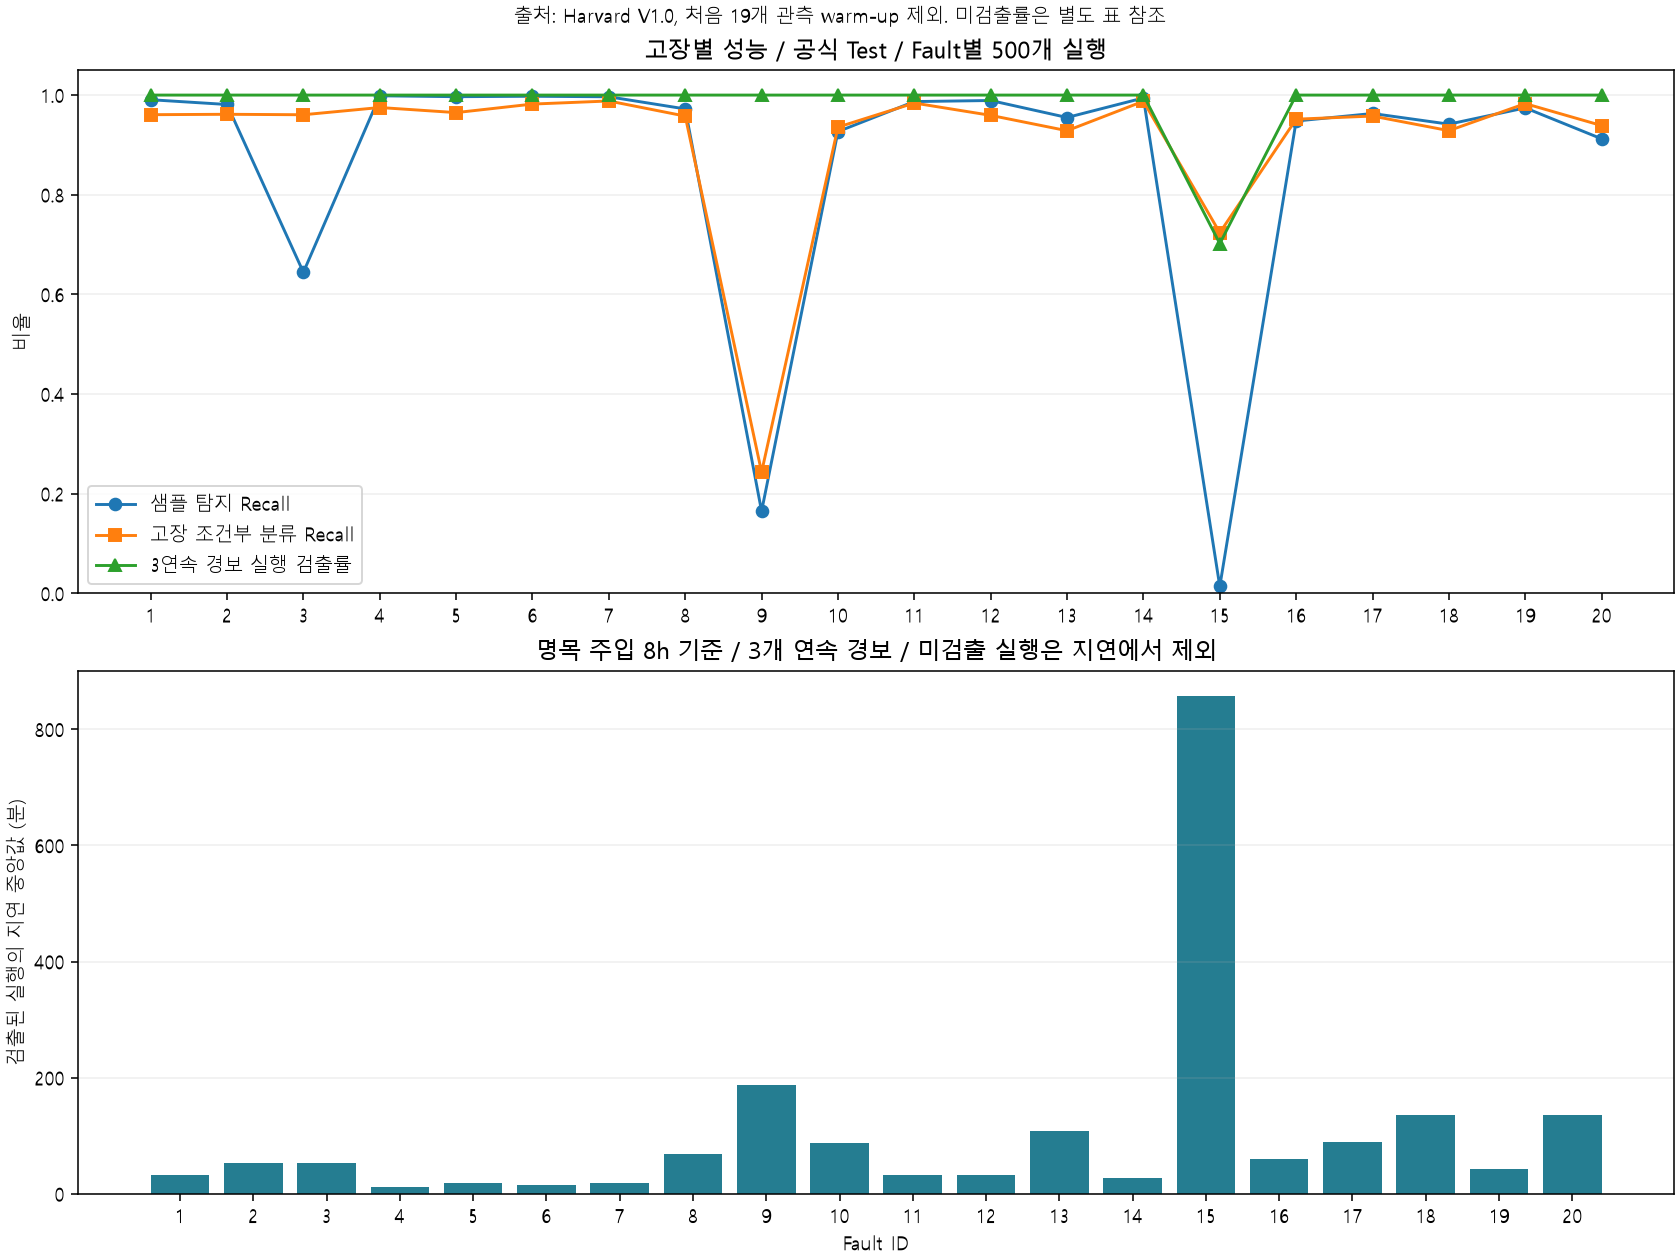

*샘플 Recall, 실행 검출률, 검출된 실행의 지연은 서로 다른 지표다.*

In [14]:
pf=per_fault.rename(columns={'fault':'Fault','post_samples':'고장 샘플 수','detection_recall':'탐지 Recall','conditional_diagnosis_recall':'조건부 분류Recall','end_to_end_recall':'end-to-end Recall'})
show_table(pf,'Fault별 탐지와 분류의 차이','primary_dense_per_fault.csv',{'고장 샘플 수':'{:,.0f}','탐지 Recall':'{:.2%}','조건부 분류Recall':'{:.2%}','end-to-end Recall':'{:.2%}'})
delay=delays[delays.system=='joint_primary'][['fault','runs','detected_runs','run_detection_rate','miss_rate','median_delay_minutes','p90_delay_minutes']].rename(columns={
 'fault':'Fault','runs':'실행 수','detected_runs':'검출 실행','run_detection_rate':'실행 검출률','miss_rate':'미검출률','median_delay_minutes':'검출 지연 중앙값(분)','p90_delay_minutes':'검출 지연 P90(분)'})
show_table(delay,'3연속 경보 기준의 실행 검출률과 지연','dense_detection_delays.csv',{'실행 검출률':'{:.2%}','미검출률':'{:.2%}','검출 지연 중앙값(분)':'{:.1f}','검출 지연 P90(분)':'{:.1f}'})
show_image('phase2/fault_performance_delay.png','샘플 Recall, 실행 검출률, 검출된 실행의 지연은 서로 다른 지표다.')

## 14. 실제 한 실행의 경보 확률과 예측 ID

기본 사례는 **Fault9, simulationRun1**이다. 맨 위의 `FAULT_TO_INSPECT`, `RUN_TO_INSPECT`를 바꾸면 다른 실행을 확인할 수 있다. 저장된 전체 Test 확률을 읽으며 모델이나 임계값을 다시 조정하지 않는다.

단일 샘플 임계값 초과와3연속 경보 확인을 구분한다. 경보 episode의 지연 계산은 주입 경계에서 카운터를 초기화했으며, 따라서 최소 지연은9분이다.

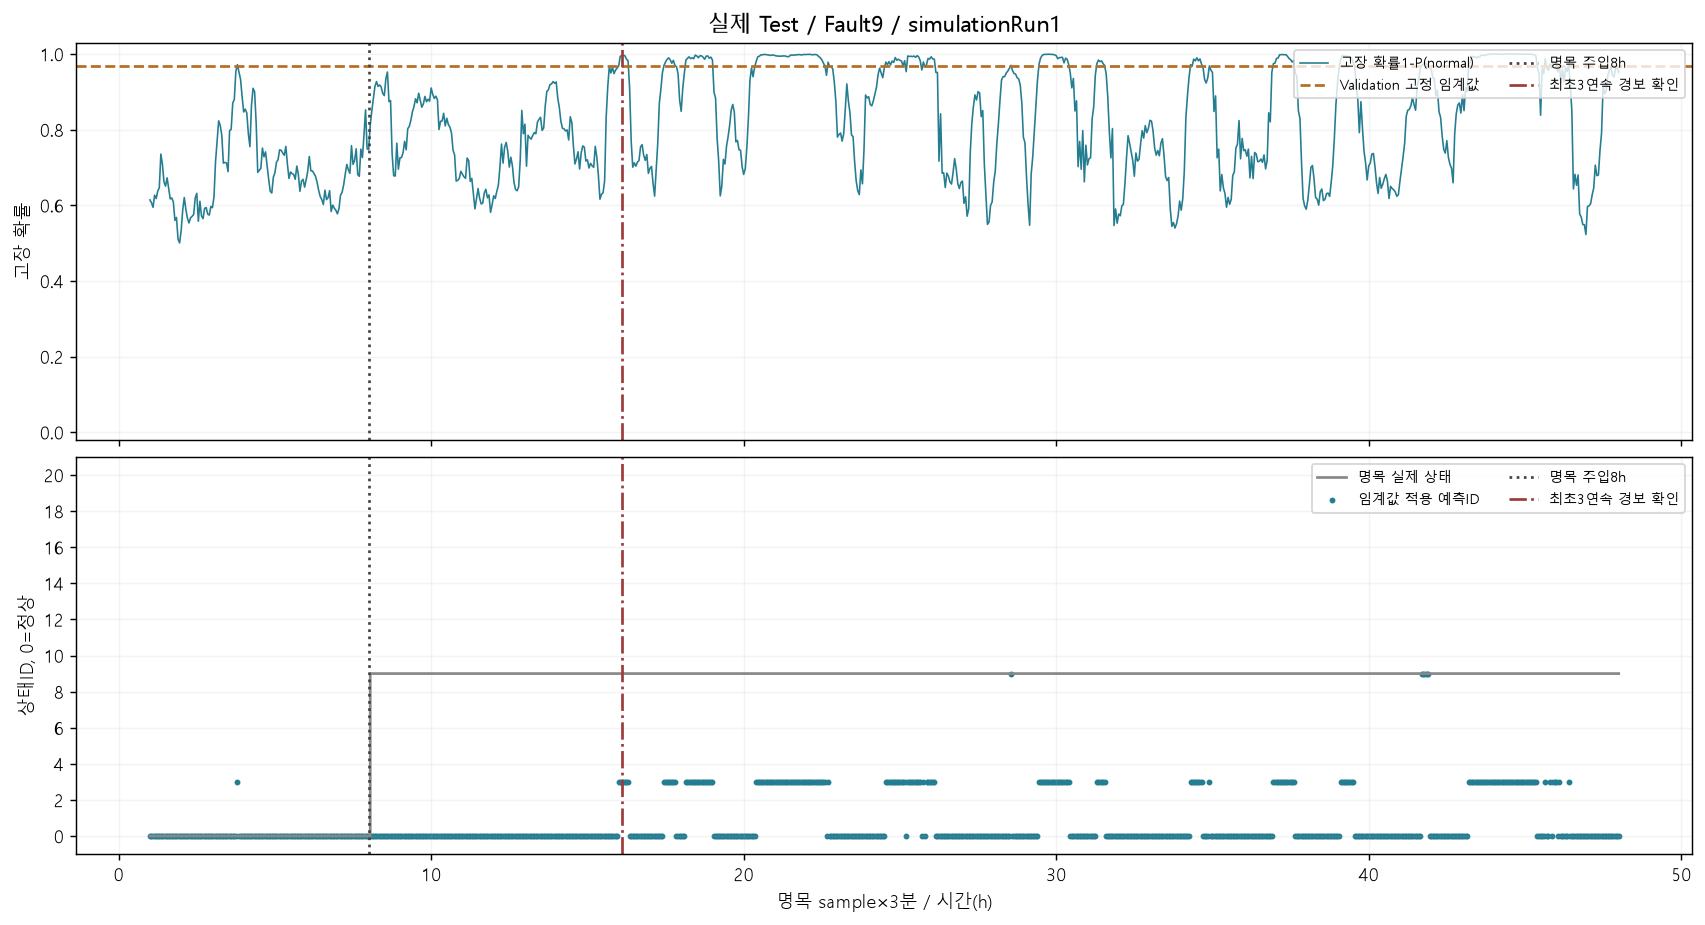

fault,run,pre_alarm_episodes,detected,first_detection_sample,detection_delay_minutes
9,1,0,True,322.000000,486.0


*출처: `dense_alarm_episodes.csv`*

정상 구간 정의,샘플 FAR
전체 정상 샘플,1.11%
정상 전용 실행,1.24%
고장 실행의 주입 전 구간,1.07%


*출처: `phase2/dense_metrics.json`*

In [15]:
probfile=ROOT/'data/processed/phase2/primary_dense_probabilities.npy'
if probfile.exists():
    probabilities=np.load(probfile,mmap_mode='r')
    start=(FAULT_TO_INSPECT*500+(RUN_TO_INSPECT-1))*941
    p=np.asarray(probabilities[start:start+941])
    sample=np.arange(20,961)
    hours=sample*3/60
    score=1-p[:,0]
    conditional_id=p[:,1:].argmax(1)+1
    gated=np.where(score>=primary['threshold'],conditional_id,0)
    actual=np.where(sample>160,FAULT_TO_INSPECT,0)
    fig,axes=plt.subplots(2,1,figsize=(13,7),sharex=True,layout='constrained')
    axes[0].plot(hours,score,lw=.9,label='고장 확률1-P(normal)',color='#257d91')
    axes[0].axhline(primary['threshold'],color='#b46d24',ls='--',label='Validation 고정 임계값')
    axes[0].set(ylim=(-.02,1.03),ylabel='고장 확률',title=f'실제 Test / Fault{FAULT_TO_INSPECT} / simulationRun{RUN_TO_INSPECT}')
    axes[1].step(hours,actual,where='post',color='#888888',label='명목 실제 상태')
    axes[1].scatter(hours,gated,s=5,color='#257d91',label='임계값 적용 예측ID')
    axes[1].set(xlabel='명목 sample×3분 / 시간(h)',ylabel='상태ID, 0=정상',ylim=(-1,21),yticks=range(0,21,2))
    selected_event=episodes[(episodes.system=='joint_primary')&(episodes.fault==FAULT_TO_INSPECT)&(episodes.run==RUN_TO_INSPECT)].iloc[0]
    for ax in axes:
        ax.axvline(8,color='#444444',ls=':',label='명목 주입8h')
        if pd.notna(selected_event.first_detection_sample):
            ax.axvline(selected_event.first_detection_sample*3/60,color='#9b3b3b',ls='-.',label='최초3연속 경보 확인')
        ax.legend(loc='upper right',ncol=2,fontsize=8);ax.grid(alpha=.15)
    plt.show()
    show_table(pd.DataFrame([selected_event[['fault','run','pre_alarm_episodes','detected','first_detection_sample','detection_delay_minutes']]]),
               '이 실행의 경보 요약','dense_alarm_episodes.csv',{'detection_delay_minutes':'{:.1f}'})
    del probabilities,p
else:
    note('확률 캐시가 없는 환경', '실행별 확률 그림 재계산에는data/processed/phase2/primary_dense_probabilities.npy가 필요하다. 저장된 노트북 출력은 그대로 읽을 수 있다.')
far=pd.DataFrame([
 ['전체 정상 샘플',primary['sample_false_alarm_rate']],
 ['정상 전용 실행',primary['normal_faultfree_FAR']],
 ['고장 실행의 주입 전 구간',primary['pre_injection_FAR']]
],columns=['정상 구간 정의','샘플 FAR'])
show_table(far,'정상 구간별 오경보율','phase2/dense_metrics.json',{'샘플 FAR':'{:.2%}'})

## 15. 불균형 처리 비교

이진 문제에서는20종 고장을 합친 양성 수가 정상보다 많다. class weight, oversampling, undersampling은 **Train에만** 적용했다. SMOTE는 사용하지 않았다. 자연 비율과 balanced는3개 seed, over/under sampling은seed42 한 번이므로 신뢰 수준이 다르다.

처리,seed,학습 창 수,Validation F1,Test F1,Test FAR
natural,42,"101,200",0.8811,0.8905,0.85%
natural,7,"101,200",0.8833,0.8922,0.95%
natural,2026,"101,200",0.8807,0.8900,0.84%
balanced,42,"101,200",0.8880,0.8960,1.01%
balanced,7,"101,200",0.8891,0.8967,1.09%
balanced,2026,"101,200",0.8884,0.8963,1.06%
undersample,42,"10,400",0.8818,0.8909,0.82%
oversample,42,"192,000",0.8883,0.8962,1.02%


*출처: `imbalance_comparison.csv`*

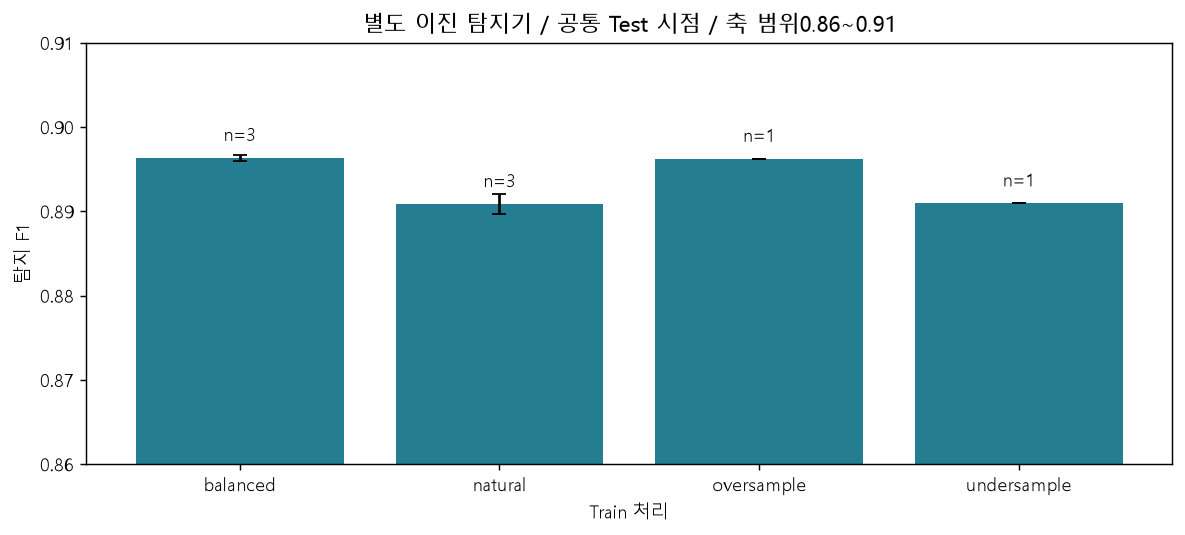

In [16]:
imbalance=read_table('imbalance_comparison.csv')
iv=imbalance[['weight','seed','train_rows','detection_f1_validation','detection_f1_test','sample_false_alarm_rate']].rename(columns={
 'weight':'처리','seed':'seed','train_rows':'학습 창 수','detection_f1_validation':'Validation F1','detection_f1_test':'Test F1','sample_false_alarm_rate':'Test FAR'})
show_table(iv,'별도 이진 XGBoost의 불균형 처리','imbalance_comparison.csv',{'학습 창 수':'{:,.0f}','Validation F1':'{:.4f}','Test F1':'{:.4f}','Test FAR':'{:.2%}'})
ig=imbalance.groupby('weight').agg(mean=('detection_f1_test','mean'),sd=('detection_f1_test','std'),n=('seed','nunique')).reset_index()
fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
ax.bar(ig.weight,ig['mean'],yerr=ig.sd.fillna(0),color='#257d91',capsize=4)
for i,r in ig.iterrows():ax.text(i,r['mean']+.002,f'n={int(r.n)}',ha='center')
ax.set(ylim=(.86,.91),ylabel='탐지 F1',xlabel='Train 처리',title='별도 이진 탐지기 / 공통 Test 시점 / 축 범위0.86~0.91')
plt.show()

## 16. SHAP·관측 센서 반응·공개 원인의 구분

주 CNN은 GradientSHAP으로, XGBoost 비교 모델은 TreeSHAP으로 설명했다. 각 Fault의 Test 실행1~5, sample240/480/960에서15개 창을 설명했다. 배경64개 창은 Train에서만 추출했다.

설명 대상은 **실제 Fault 클래스의 raw logit**이다. 잘못 분류한 창도 그 클래스에 대한 기여를 계산한다. 원 변수별 순위는 시차·파생 특징의 절대 기여를 합친 것이며, 인과 효과나 실제 원인 순위가 아니다. 냉각수 출구 온도와 원인인 입구 온도도 같은 변수가 아니다.

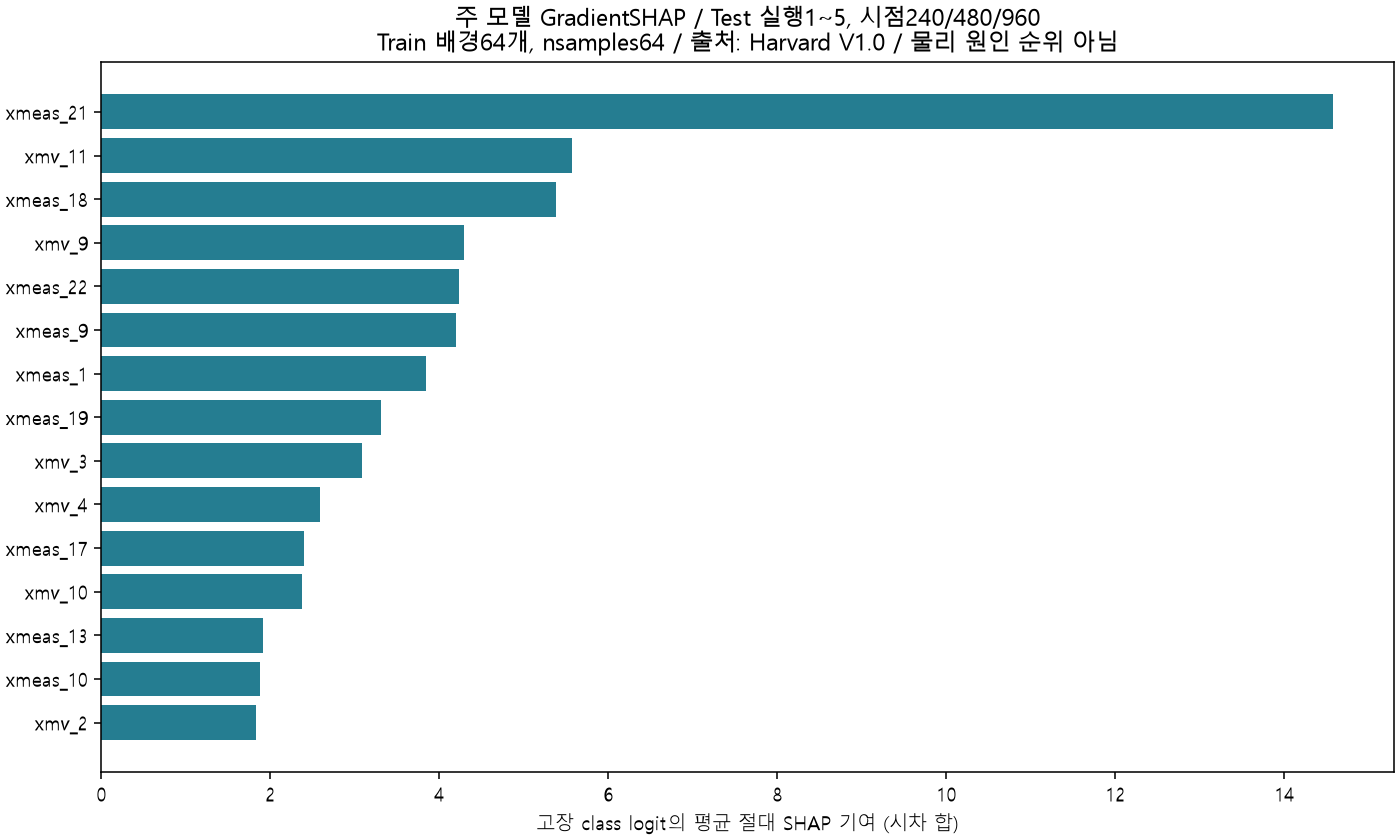

*GradientSHAP: 15개 창/Fault, Train 배경64개, nsamples64. 전체 Test의 대표성을 보장하지 않는다.*

순위,변수,평균 절대 기여(시차합),설명 창 수
1,xmeas_21,6.65788,15
2,xmeas_22,4.23914,15
3,xmeas_18,3.83064,15
4,xmv_11,3.49943,15
5,xmv_9,3.43864,15
6,xmeas_9,2.67441,15
7,xmeas_17,2.03828,15
8,xmeas_19,1.75314,15
9,xmv_3,1.73302,15
10,xmv_2,1.65557,15


*출처: `shap_sensor_rankings.csv`*

Fault,공개 시나리오(A 참조),실제 B 변화 상위3,주 모델 SHAP 상위3
1,A/C 원료 비율(B 일정),"xmeas_1, xmv_3, xmeas_4","xmeas_1, xmv_3, xmeas_18"
2,B 조성(A/C 일정),"xmeas_34, xmeas_10, xmv_6","xmeas_10, xmeas_34, xmeas_28"
3,D 원료 온도,"xmeas_21, xmv_10, xmeas_20","xmeas_21, xmeas_18, xmv_9"
4,Reactor 냉각수 입구 온도,"xmv_10, xmeas_20, xmv_9","xmv_10, xmeas_21, xmv_11"
5,Condenser/Separator 냉각수 입구 온도,"xmv_11, xmeas_11, xmeas_19","xmv_11, xmeas_17, xmeas_21"
6,A 원료 공급 손실,"xmeas_16, xmeas_7, xmeas_31","xmv_11, xmv_3, xmeas_1"
7,C header 압력 손실,"xmv_4, xmv_9, xmeas_19","xmv_4, xmeas_18, xmeas_21"
8,A/B/C 원료 조성,"xmeas_29, xmeas_31, xmeas_25","xmv_9, xmeas_18, xmeas_1"
9,D 원료 온도,"xmv_9, xmeas_20, xmeas_19","xmeas_21, xmeas_22, xmeas_18"
10,C 원료 온도,"xmv_9, xmeas_19, xmeas_18","xmeas_21, xmeas_18, xmv_9"


*출처: `fault_cause_comparison.csv; b_fault_sensor_response.csv`*

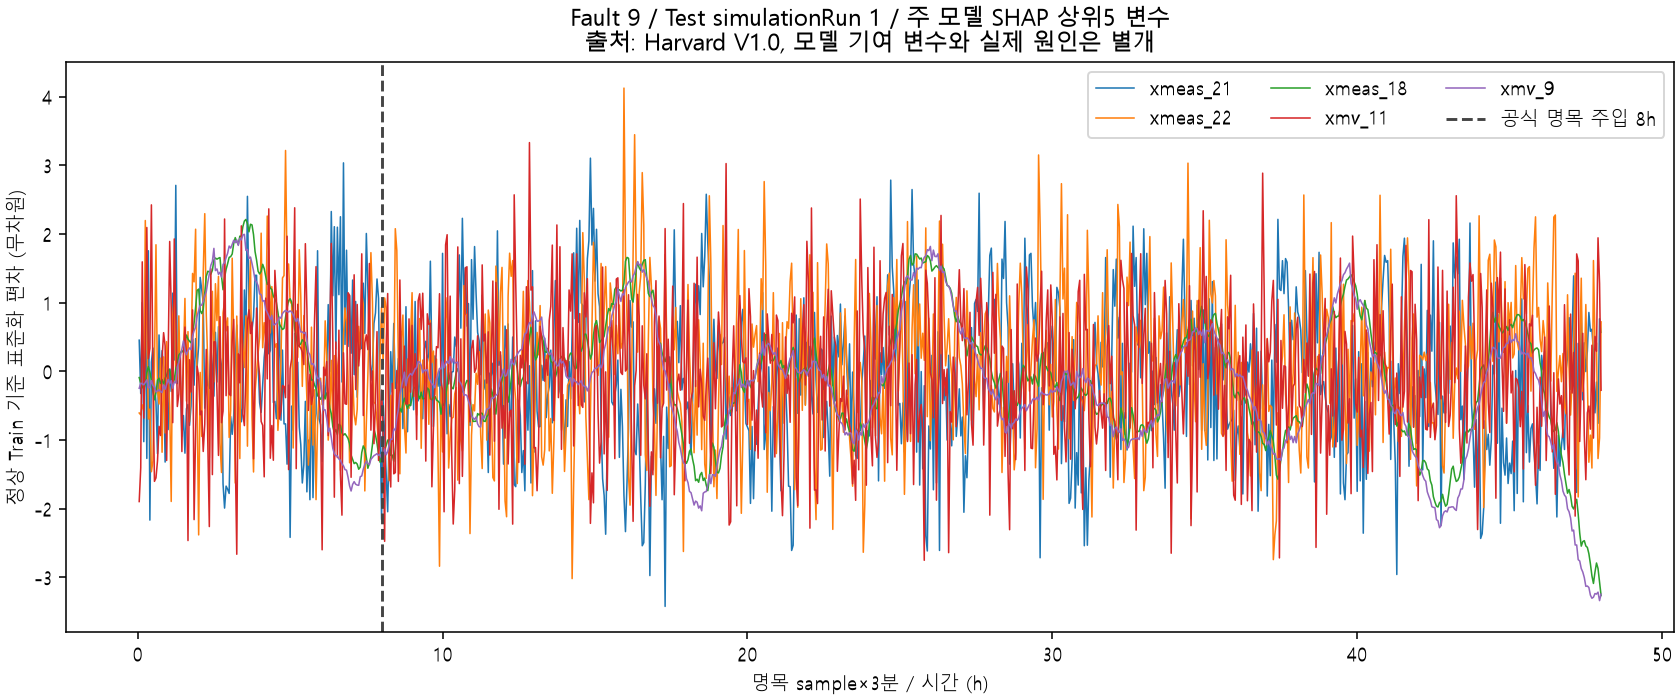

*실제 B 센서 반응. 정상 Train 기준 표준화, Test run1. SHAP 순위 cohort는run1~5의15개 창이다.*

In [17]:
show_image('phase2/primary_shap.png','GradientSHAP: 15개 창/Fault, Train 배경64개, nsamples64. 전체 Test의 대표성을 보장하지 않는다.')
sr=shap_rank[(shap_rank.model_id==lock['primary_model'])&(shap_rank.fault==FAULT_TO_INSPECT)&(shap_rank['rank']<=10)]
sv=sr[['rank','variable','mean_absolute_attribution','explained_samples']].rename(columns={'rank':'순위','variable':'변수','mean_absolute_attribution':'평균 절대 기여(시차합)','explained_samples':'설명 창 수'})
show_table(sv,f'Fault{FAULT_TO_INSPECT} 주 모델의 기여 상위10개 변수','shap_sensor_rankings.csv',{'평균 절대 기여(시차합)':'{:.5f}'})
cause=read_table('fault_cause_comparison.csv')[['fault','public_scenario_reference','observed_top3','shap_top3']].rename(columns={
 'fault':'Fault','public_scenario_reference':'공개 시나리오(A 참조)','observed_top3':'실제 B 변화 상위3','shap_top3':'주 모델 SHAP 상위3'})
show_table(cause,'정의·측정 반응·모델 기여의 대조','fault_cause_comparison.csv; b_fault_sensor_response.csv')
show_image(f'phase2/fault_{FAULT_TO_INSPECT:02d}_shap_response.png',
           '실제 B 센서 반응. 정상 Train 기준 표준화, Test run1. SHAP 순위 cohort는run1~5의15개 창이다.')
note('원인 적중률은 계산하지 않았다',
     'B 시뮬레이터의 직접 원인-측정 열 대응 및 구현 동일성이 충분히 검증되지 않았다. '
     'Fault16~20의 공개 원인은UNKNOWN으로 유지했다. 모델 기여, 관측 반응, 실제 원인을 같은 정답으로 취급하지 않는다.')

## 17. 미지 고장 실험

별도 이진 XGBoost에서 **Fault3·9·15의 양성 학습 예시를 제외**했다. 임계값을 정할 때도 이 세 고장의 양성 검증 예시를 제외했다. 이 결과는20종 지도 분류 성능과 다른 과제다.

이 실험에서 제외 고장을 거의 탐지하지 못했다. 전체 F1이 높다는 이유로 새로운 고장에 일반화한다고 결론내리면 안 된다. 결과는 지정한 세 고장에 한정된다.

모델,미지 Recall,미지 F1,미지 ROC-AUC,기학습 Recall,전체 정상 FAR
UnknownBinaryXGBoost_Statistical_balanced_s2026,2.73%,0.0524,0.6306,95.75%,1.04%
UnknownBinaryXGBoost_Statistical_balanced_s42,2.50%,0.0480,0.6320,95.74%,0.94%
UnknownBinaryXGBoost_Statistical_balanced_s7,2.56%,0.0490,0.6318,95.69%,0.99%


*출처: `test_comparison.csv; UnknownBinaryXGBoost metadata`*

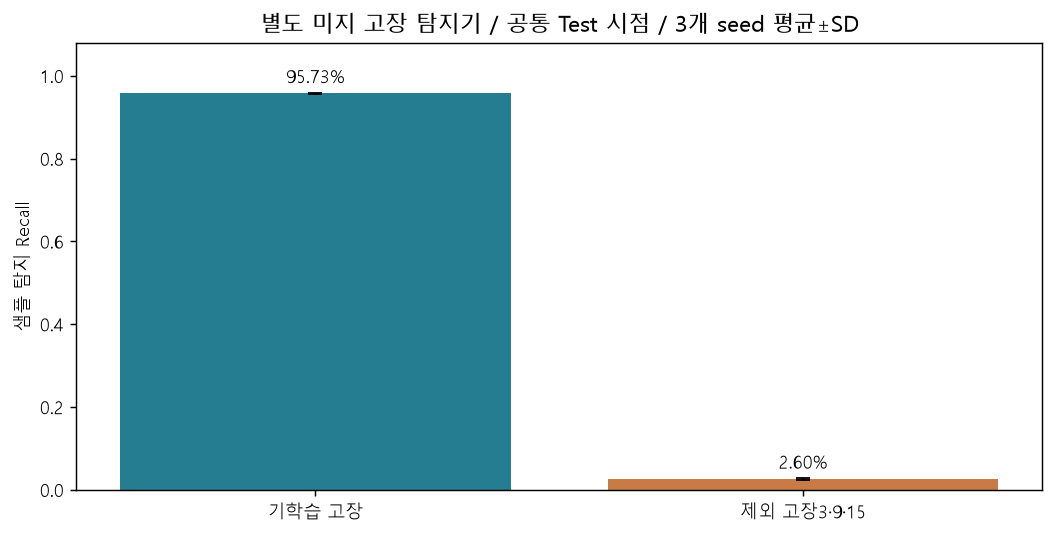

In [18]:
unknown=test_models[test_models.model_id.str.startswith('Unknown')]
uv=unknown[['model_id','unseen_faults_detection_recall','unseen_faults_detection_f1','unseen_faults_detection_roc_auc','seen_faults_detection_recall','sample_false_alarm_rate']].rename(columns={
 'model_id':'모델','unseen_faults_detection_recall':'미지 Recall','unseen_faults_detection_f1':'미지 F1','unseen_faults_detection_roc_auc':'미지 ROC-AUC','seen_faults_detection_recall':'기학습 Recall','sample_false_alarm_rate':'전체 정상 FAR'})
show_table(uv,'학습에서 제외한3종 고장 탐지','test_comparison.csv; UnknownBinaryXGBoost metadata',
           {'미지 Recall':'{:.2%}','미지 F1':'{:.4f}','미지 ROC-AUC':'{:.4f}','기학습 Recall':'{:.2%}','전체 정상 FAR':'{:.2%}'})
fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
values=[unknown.seen_faults_detection_recall.mean(),unknown.unseen_faults_detection_recall.mean()]
errors=[unknown.seen_faults_detection_recall.std(),unknown.unseen_faults_detection_recall.std()]
ax.bar(['기학습 고장','제외 고장3·9·15'],values,yerr=errors,color=['#257d91','#c87b45'],capsize=4)
for i,v in enumerate(values):ax.text(i,v+.025,f'{v:.2%}',ha='center')
ax.set(ylim=(0,1.08),ylabel='샘플 탐지 Recall',title='별도 미지 고장 탐지기 / 공통 Test 시점 / 3개 seed 평균±SD')
plt.show()

## 18. 실행 비용·모델 번들·검증 결과

주 모델 checkpoint는 약152KiB로 작지만 Python·PyTorch 런타임 크기는 포함하지 않는다. 아래 지연 측정은 **warm-up 이후 정규화·전송·모델·softmax**를 포함하며 디스크 읽기와 창 생성은 제외했다. GPU가 단일 창에서도 CPU보다 항상 빠른 것은 아니다.

모델 번들에는 주 CNN, 별도 이진 XGBoost, scaler, schema, threshold, 추론 코드와 체크섬이 있다. 입력은 한 실행의 연속 관측이어야 하며 유한값만 허용한다.

In [19]:
latency=read_table('latency_benchmark.csv')[['device','batch','repeats','median_batch_ms','p95_batch_ms','median_ms_per_window']].rename(columns={
 'device':'장치','batch':'Batch','repeats':'반복','median_batch_ms':'Batch 중앙값(ms)','p95_batch_ms':'Batch P95(ms)','median_ms_per_window':'관측창당 중앙값(ms)'})
show_table(latency,'현재 PC에서 측정한 warmed 추론 지연','latency_benchmark.csv',
           {c:'{:.4f}' for c in latency.columns if '(ms)' in c})
validation=read_json(SOURCES/'artifact_validation.json')
testlog=(SOURCES/'test_validation.txt').read_text(encoding='utf-8')
test_count=int(re.search(r'Ran (\d+) tests',testlog).group(1))
checks=pd.DataFrame([
 ['실데이터 구조·누수 자동 테스트',f'{test_count}개 통과','실행 분할·공유prefix·미래 참조·창 경계·라벨·scaler·제외 고장'],
 ['기존 Phase2 노트북','5개 오류 없이 실행','06~10 노트북 실행 기록'],
 ['번들 체크섬',f"{validation['manifest_files_verified']}개 파일 검증",'가중치·scaler·입력 schema·추론 코드 등'],
 ['휴대용 CPU / GPU 평가 확률 최대 차이',f"{validation['portable_cpu_dense_gpu_max_probability_error']:.6f}",'검사한181개 창, 절대 허용오차0.001'],
 ['검사한181개 창의 경보 판정 일치',f"{validation['cpu_gpu_threshold_decision_agreement_in_checked_181_windows']:.0%}",'전체 Test CPU/GPU 판정 일치를 보장하지 않음'],
 ['미래 데이터 변경 영향 없음',str(validation['no_future_reference']),'추론 API에서도 확인']
],columns=['검증','결과','범위'])
show_table(checks,'실행·누수·배포 검증','test_validation.txt; artifact_validation.json; phase2/notebook_validation.json')
display(Markdown(f'**Test 비교에 기록된 학습 설정 수:** {test_models.model_id.nunique()}개. seed·가중치·특징·별도 실험 조합을 포함한다.'))

장치,Batch,반복,Batch 중앙값(ms),Batch P95(ms),관측창당 중앙값(ms)
cpu,1,100,0.2249,0.2387,0.2249
cpu,256,100,3.2907,3.4935,0.0129
cuda,1,100,0.5532,0.6954,0.5532
cuda,256,100,1.5135,1.7829,0.0059


*출처: `latency_benchmark.csv`*

검증,결과,범위
실데이터 구조·누수 자동 테스트,14개 통과,실행 분할·공유prefix·미래 참조·창 경계·라벨·scaler·제외 고장
기존 Phase2 노트북,5개 오류 없이 실행,06~10 노트북 실행 기록
번들 체크섬,8개 파일 검증,가중치·scaler·입력 schema·추론 코드 등
휴대용 CPU / GPU 평가 확률 최대 차이,0.000552,"검사한181개 창, 절대 허용오차0.001"
검사한181개 창의 경보 판정 일치,100%,전체 Test CPU/GPU 판정 일치를 보장하지 않음
미래 데이터 변경 영향 없음,True,추론 API에서도 확인


*출처: `test_validation.txt; artifact_validation.json; phase2/notebook_validation.json`*

**Test 비교에 기록된 학습 설정 수:** 44개. seed·가중치·특징·별도 실험 조합을 포함한다.

## 19. 결과 해석의 한계와 다음 실험

현재 결과를 좋게 보이도록 어려운 고장을 제외하거나 Test에서 임계값을 다시 조정하지 않았다. 다음 변경을 평가하려면 이미 확인한 Test에 반복 최적화하지 말고 새로운 미사용 평가 실행을 확보해야 한다.

In [20]:
limitations=pd.DataFrame([
 ['Fault9·15 진단','end-to-end Recall 약0.04%·0%','탐지 실패와 잘못된 ID의 원인을 분리하고 새 평가 실행으로 검증'],
 ['고장 초기 과도 학습','Train endpoint120분 간격, 최초약2시간 창 부족','Train 초기 구간을 촘촘하게 구성하는 새 실험'],
 ['미지 고장 일반화','제외3종 Recall 약2.6%','정상 기반 이상 탐지·새 고장군의 별도 평가'],
 ['오경보 목표','Validation FAR≤1%였지만 Test는1.11%','미사용 검증 실행에서 경보·보정 규칙을 사전 결정'],
 ['주입·운전기간 차이','Training1h/25h, Test8h/48h','시간·운전 조건 이동에 대한 별도 일반화 실험'],
 ['독립 실험 수','같은run의 정상 prefix 공유','행 단위 분할 금지, family 단위 신뢰구간 유지'],
 ['물리 원인 해석','직접 원인-측정 대응 및 B 구현 미확인','공개 원인과 측정·조작·보상 변수의 대응표 보완'],
 ['설명 대표성','SHAP은15개 창/Fault의 근사 설명','더 넓은 시점·실행 및 설명 안정성 검증'],
 ['실제 설비 적용','화학공정 시뮬레이션만 평가','운전모드·실측 자료·결측/센서 이상 조건 검증'],
 ['평가 자료 노출','Phase1에서 Test 품질·일부 통계 조사','완전히 미노출인 외부 Test 확보']
],columns=['한계','현재 증거','다음 단계'])
show_table(limitations,'현재 결과의 사용 범위','Phase1/Phase2 감사·실험 설계·평가 산출물')

한계,현재 증거,다음 단계
Fault9·15 진단,end-to-end Recall 약0.04%·0%,탐지 실패와 잘못된 ID의 원인을 분리하고 새 평가 실행으로 검증
고장 초기 과도 학습,"Train endpoint120분 간격, 최초약2시간 창 부족",Train 초기 구간을 촘촘하게 구성하는 새 실험
미지 고장 일반화,제외3종 Recall 약2.6%,정상 기반 이상 탐지·새 고장군의 별도 평가
오경보 목표,Validation FAR≤1%였지만 Test는1.11%,미사용 검증 실행에서 경보·보정 규칙을 사전 결정
주입·운전기간 차이,"Training1h/25h, Test8h/48h",시간·운전 조건 이동에 대한 별도 일반화 실험
독립 실험 수,같은run의 정상 prefix 공유,"행 단위 분할 금지, family 단위 신뢰구간 유지"
물리 원인 해석,직접 원인-측정 대응 및 B 구현 미확인,공개 원인과 측정·조작·보상 변수의 대응표 보완
설명 대표성,SHAP은15개 창/Fault의 근사 설명,더 넓은 시점·실행 및 설명 안정성 검증
실제 설비 적용,화학공정 시뮬레이션만 평가,운전모드·실측 자료·결측/센서 이상 조건 검증
평가 자료 노출,Phase1에서 Test 품질·일부 통계 조사,완전히 미노출인 외부 Test 확보


*출처: `Phase1/Phase2 감사·실험 설계·평가 산출물`*

## 20. 재현 방법과 산출물 안내

노트북의 `Run All`은 표·그림을 재구성한다. 저장된 출력만 읽을 때는 GPU나 원본 RData를 다시 읽을 필요가 없다. 재실행에는 이 프로젝트의 `reports/`, 설정·모델 선택 기록과 분석 패키지가 필요하다. 14절 실행별 확률 그림의 재계산만 대형 확률 캐시를 사용한다.

학습부터 전체 재현은 프로젝트 루트의 아래 명령을 사용한다. 기존 캐시·모델을 재사용하며, 설정이 바뀌면 캐시 재사용을 거부한다. 원본 데이터는 수정하지 않는다.

```powershell
.\run_phase2.ps1
# 저장된 평가 결과로 보고서·그림 재생성
.\run_phase2.ps1 -ReportsOnly
```

새 데이터 한 실행의 추론:

```powershell
python src/models/inference.py --bundle models/phase2/final_model --input one_run.csv --output predictions.csv
```

| 산출물 | 위치 |
|---|---|
| 모델 성능·특징 요약 | `reports/markdown/12_model_card.md` |
| 전체 연구 보고서 | `reports/markdown/11_final_research_report.md` |
| 실험 설계·모델 비교·지연·XAI·연구 질문 | `reports/markdown/07~13` |
| 재사용 가능한 모델 번들 | `models/phase2/TEP_final_model.zip` |
| 학습·특징·평가·추론 코드 | `src/data`, `src/features`, `src/models`, `src/evaluation` |
| 버전·설정·선택·검증 기록 | `requirements-lock.txt`, `configs/phase2.json`, `reports/sources/phase2` |

**자료 출처:** [GitHub Dataset A](https://github.com/Blound04/tennessee-eastman-dataset), [Harvard Dataset B V1.0](https://doi.org/10.7910/DVN/6C3JR1). 실제 수치와 그림은 위의 로컬 감사·학습·평가 산출물에서 읽었다. 공정의 물리적 설명과 측정 반응, 모델 기여도를 구분하여 해석한다.

In [21]:
environment=read_json(SOURCES/'environment.json')
env=pd.DataFrame(environment['packages'].items(),columns=['패키지','실제 학습 버전'])
show_table(env,'학습 환경 버전','reports/sources/phase2/environment.json')
display(Markdown(f'**GPU:** {environment["gpu"]} · **Torch CUDA:** {environment["torch_cuda"]}'))
assert primary['samples']==9_880_500
assert test_models.model_id.nunique()==44
assert len(per_fault)==20 and set(per_fault.fault)==set(range(1,21))
assert len(unknown)==3
display(Markdown('**노트북 수치 일관성 확인 완료:** 모델44개 설정, 고장20종, 전체 유효 Test9,880,500시점.'))

패키지,실제 학습 버전
numpy,2.3.5
pandas,3.0.1
scikit-learn,1.9.1
xgboost,3.4.1
torch,2.5.1+cu121
shap,0.54.1
pyreadr,0.5.9
matplotlib,3.11.2
joblib,1.6.0


*출처: `reports/sources/phase2/environment.json`*

**GPU:** NVIDIA GeForce RTX 3060 Laptop GPU · **Torch CUDA:** 12.1

**노트북 수치 일관성 확인 완료:** 모델44개 설정, 고장20종, 전체 유효 Test9,880,500시점.